# Where is childcare access weakest for young families, and will ECDA's planned centres fix it?

**BT4015 Group 2, the project in one notebook.** This is the reader's version of our 12 November
presentation: the same arc, the same figures, and every headline number read live from the files in
`output/` and `figures/` that the stage notebooks wrote. It recomputes nothing heavy and runs in a
few seconds. Each section names the notebook that produced its evidence, so any figure can be traced
to the code that made it ([run_all.ipynb](run_all.ipynb) regenerates all of it).

The story has one question, two suspects that are cleared, one culprit found with an instrument we
built for the purpose, and a check of that instrument against an outside witness before the verdict.

| Part | Question it answers | Notebooks |
|---|---|---|
| 1. The question and the data | What are we asking, and from what? | `1_01`–`1_08` |
| 2. Setting the scene | Where are the children, where are the centres? | `2_01`–`2_05`, `3_04` |
| 3. Suspect one: price | Do fees cluster, and do they follow income? | `3_01`–`3_03` |
| 4. Suspect two: distance | Is walking access unequal? | `2_04`, `3_07` |
| 5. The instrument: supply pressure | How many children does each reachable centre serve? | `3_05`, `3_06` |
| 6. The witness: ECDA's pipeline | Did ECDA, independently, put centres where our index is red? | `3_08` |
| 7. The verdict | Recommendations, conclusion, limitations | — |

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import pyogrio
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
assert (ROOT / "src" / "bt4015").is_dir(), "run this notebook from the repository root"
OUT, FIG = ROOT / "output", ROOT / "figures"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def show(path, width=880):
    """Display a saved figure at a readable width."""
    display(Image(filename=str(path), width=width))


def table(df, floatfmt="{:,.1f}"):
    """Print a small table without the index, numbers lightly formatted."""
    display(df.style.hide(axis="index").format(floatfmt, subset=df.select_dtypes("number").columns))


def read_summary_stat(path, label):
    """Pull one bold number out of a Daryl-style analysis_summary.md, e.g. 'Observed I: **0.5110**'."""
    match = re.search(rf"{re.escape(label)}:\s*\*\*([-\d.]+)\*\*", Path(path).read_text())
    return float(match.group(1))

## 1. The question, and what we built it from

Singapore is adding about 40,000 childcare places between 2025 and 2029. Will they land where
families need them? We asked three things: where families and centres are concentrated and where new
centres should go; how fees are spread and whether they follow income; and how walking access varies
across HDB neighbourhoods. Behind all three is one question with three possible answers: when access
is poor, is it because of **distance**, **price**, or **capacity**?

Everything comes from public data: ECDA's centre and fee listings (October 2026), HDB's block polygons
and attributes, SingStat's population by subzone, age and dwelling type, the Master Plan 2019 subzone
boundaries, the Census household-income table, and the OpenStreetMap walking network. Stage 1 joins
the HDB polygons to their attributes (the two share no key; we decode LTA road codes and match 99% of
blocks), allocates children to blocks by flat type, geocodes the centres, and routes every block to
every centre on the real footpath network with OSRM.

In [2]:
# 1. The three objects every later step uses: residential blocks with children, centres, planned centres.
blocks = pd.read_csv(OUT / "hdb_access_children.csv")
centres = pyogrio.read_dataframe(OUT / "childcare_centres_2026.gpkg", layer="centres", read_geometry=False)
planned = pyogrio.read_dataframe(OUT / "childcare_centres_2026.gpkg", layer="planned", read_geometry=False)
subzones = pd.read_csv(OUT / "subzone_stats.csv")

fee = pd.to_numeric(centres["FULL_DAY_SC_NURSERY_FEE"], errors="coerce")
print(f"residential HDB blocks (origins):        {len(blocks):,}")
print(f"children aged 0-6 on those blocks:       {blocks['child_0_6'].sum():,.0f}  "
      f"(of {blocks['child_pop_0_9'].sum():,.0f} aged 0-9)")
print(f"centres operating, Oct 2026 (destinations): {len(centres):,}  by service model "
      f"{centres['service_model'].value_counts().to_dict()}")
print(f"centres with a listed full-day nursery fee: {int((fee > 0).sum()):,}")
print(f"planned centres held out of the baseline:   {len(planned)}")
print(f"subzones with residential HDB:              {int(subzones['has_hdb'].sum())} of {len(subzones)}")
print(f"walk matrix:                                {len(blocks):,} blocks x {len(centres):,} centres, OSRM foot profile")

residential HDB blocks (origins):        10,769
children aged 0-6 on those blocks:       176,409  (of 259,910 aged 0-9)
centres operating, Oct 2026 (destinations): 1,796  by service model {'CC': 1467, 'KN': 183, 'DS': 84, 'EYC-DS': 57, 'EYC': 5}
centres with a listed full-day nursery fee: 1,586
planned centres held out of the baseline:   13
subzones with residential HDB:              159 of 332
walk matrix:                                10,769 blocks x 1,796 centres, OSRM foot profile


**The assumptions we made, stated up front** (deck slide 7)

- Snapshot is mid-2026: June population, October centre listing.
- Demand is children aged 0 to 6 on HDB blocks: the 0–4 band plus each subzone's own share of 5–6
  within 5–9 (flat 40% where the subzone is too small to estimate). Children in private housing are
  not counted, so centres beside condominiums look less pressured than they are.
- Every centre counts as one unit. ECDA publishes vacancy status, not places, so capacity is unknown.
- "Reachable" means within a ten-minute walk on the OpenStreetMap foot network.
- The 13 planned centres are held out of the baseline and tested separately in part 6.

Three suspects, then: distance, price and capacity. We take them in turn.

## 2. Setting the scene (ESDA)

Before testing anything, the raw geography. Children aged 0–6 per square kilometre by subzone, then
the same children as a smoothed surface with the 1,796 centres on top. The young families are in the
north-east: Punggol and Sengkang above 2,500 children per km², with Tampines, Woodlands and Yishun
next; the centre of the island is nearly empty of children. Centres broadly follow children, but the
Punggol and Sengkang hotspots are hotter than the dots around them. That is the first hint of the ending.
(`3_04`, `2_02`.)

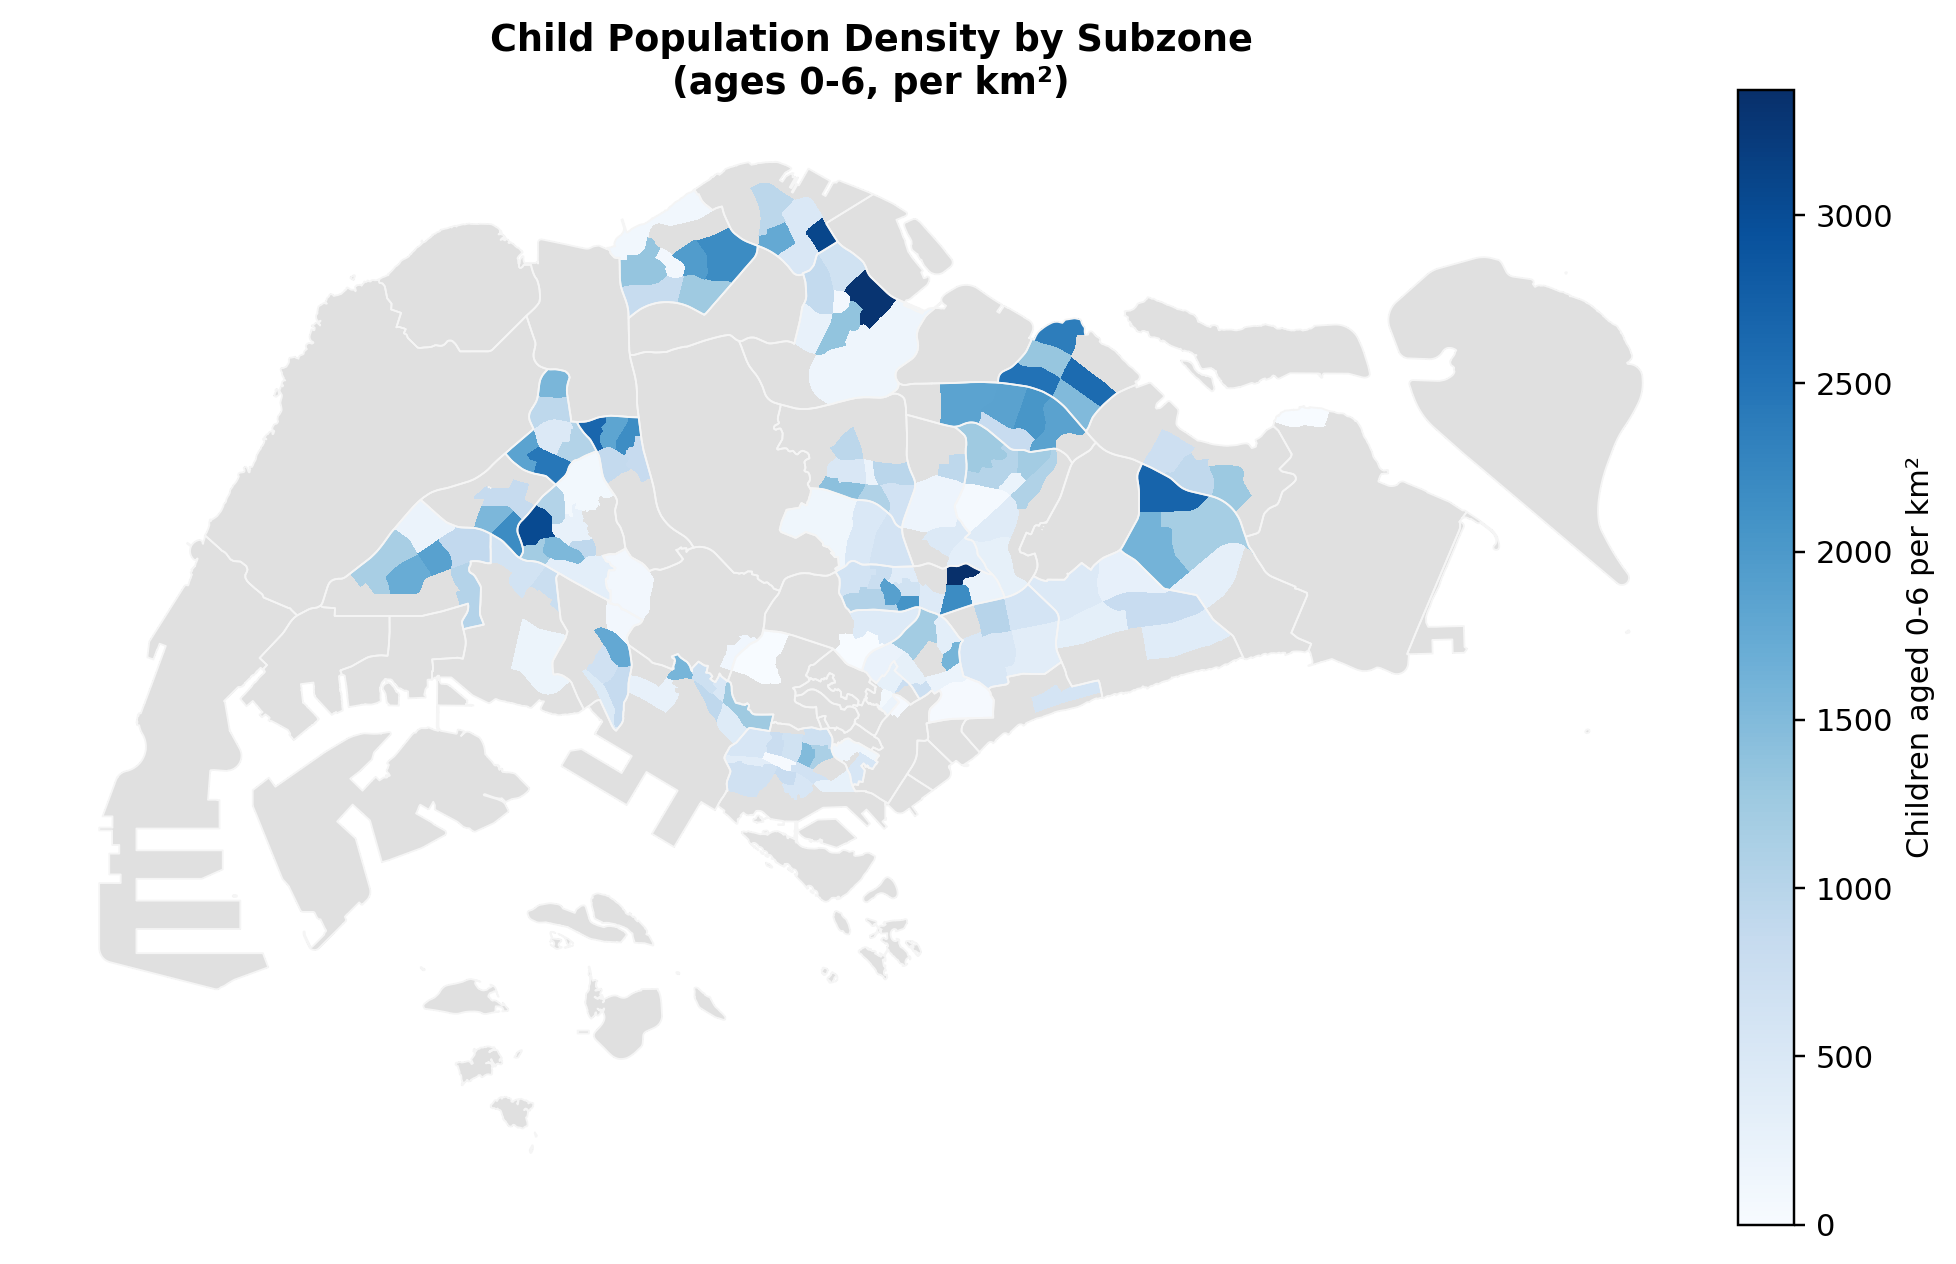

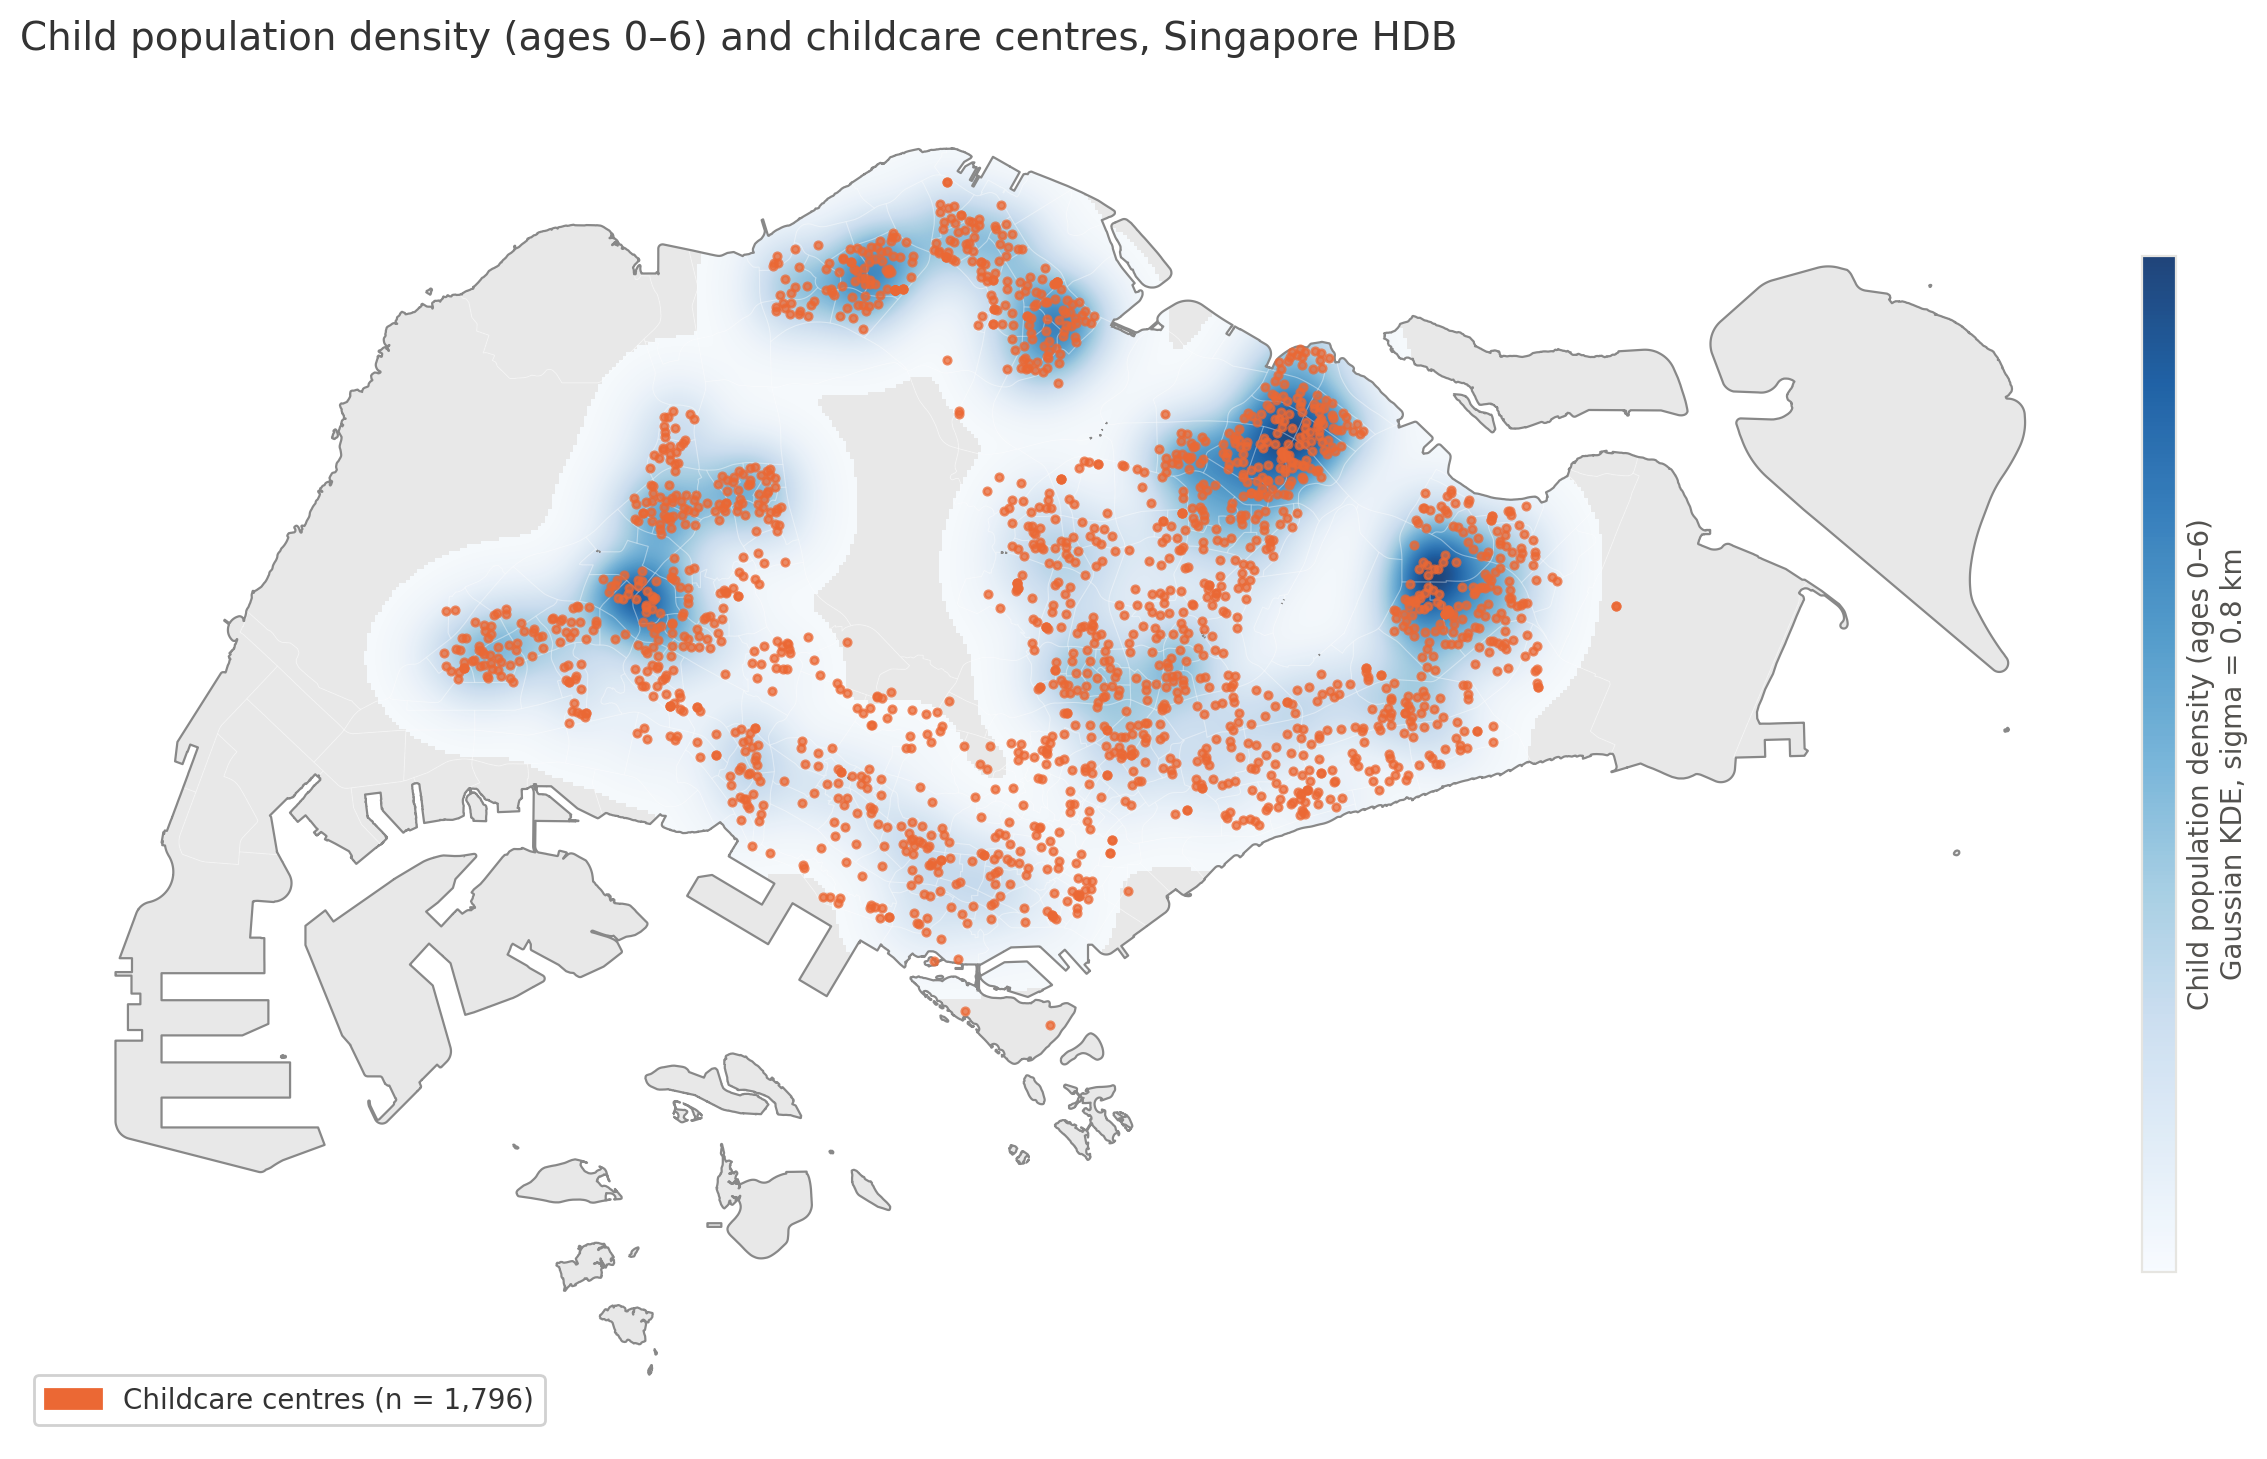

Child density is spatially clustered: global Moran's I = 0.187, pseudo-p = 0.001 (159 HDB subzones, KNN-4, 999 permutations; 3_04)


In [3]:
show(OUT / "spatial_autocorrelation_child_population" / "child_density_choropleth.png", 820)
show(FIG / "child_centre_kde_map.png", 820)
child_I = read_summary_stat(OUT / "spatial_autocorrelation_child_population" / "analysis_summary.md", "Observed I")
child_p = read_summary_stat(OUT / "spatial_autocorrelation_child_population" / "analysis_summary.md", "Permutation pseudo-p")
print(f"Child density is spatially clustered: global Moran's I = {child_I:.3f}, pseudo-p = {child_p:.3f} "
      f"(159 HDB subzones, KNN-4, 999 permutations; 3_04)")

**Do centres follow children?** One dot per HDB subzone with at least 100 children, both axes logged.
The slope of log centres on log children is the supply elasticity: a subzone with 10% more children
has about 6.5% more centres. Supply follows demand, but at two-thirds the rate, so the biggest estates
have the fewest centres per child. (`2_05`.)

supply elasticity: 0.65 (R-squared 0.57, n = 140 subzones); 1.0 would be proportional supply


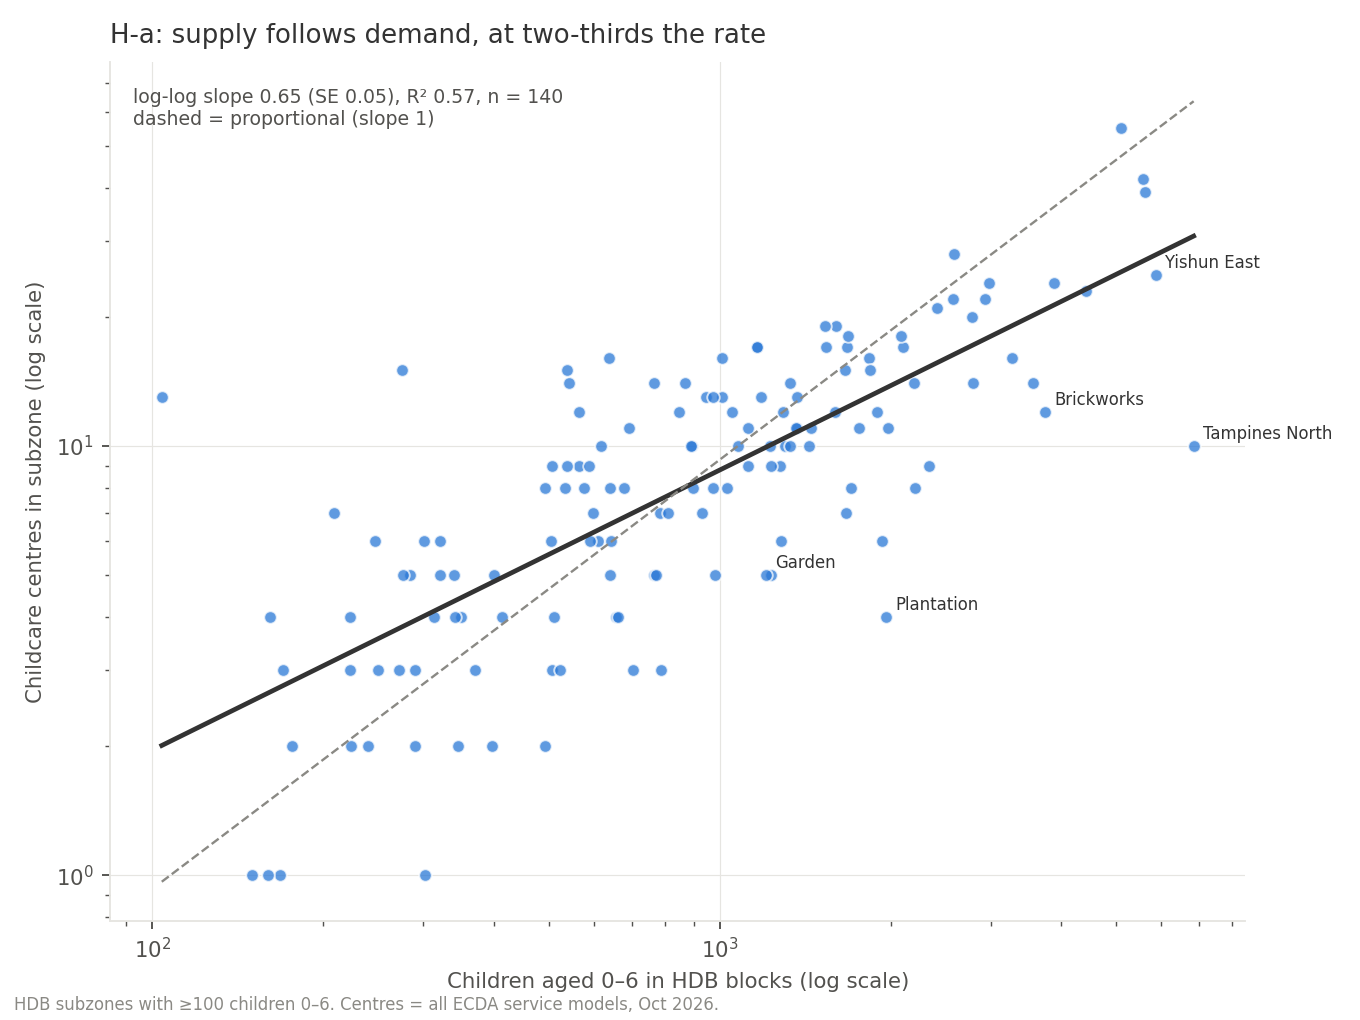

In [4]:
# 1. The same fit as 2_05: OLS of log(centres) on log(children 0-6), HDB subzones with >= 100 children.
ha = subzones[(subzones["has_hdb"] == 1) & (subzones["children_0_6"] >= 100) & (subzones["centres_n"] > 0)]
slope, intercept = np.polyfit(np.log(ha["children_0_6"]), np.log(ha["centres_n"]), 1)
fitted = intercept + slope * np.log(ha["children_0_6"])
r2 = 1 - ((np.log(ha["centres_n"]) - fitted) ** 2).sum() / ((np.log(ha["centres_n"]) - np.log(ha["centres_n"]).mean()) ** 2).sum()
print(f"supply elasticity: {slope:.2f} (R-squared {r2:.2f}, n = {len(ha)} subzones); 1.0 would be proportional supply")
show(FIG / "ha_centres_vs_children.png", 760)

**Is either pattern random?** Ripley's K for the 10,769 blocks and the 1,796 centres, against 199
simulated random patterns in the same window. Both sit three to five times above the random reference
at every distance from 100 m to 1.5 km. Both are clustered; the question is whether they are clustered
*in proportion*. (`2_03`.)

pattern,analysed_n,max_L_minus_r_m,global_p,significant_clustering_5pct
HDBs,"10,769.000","1,455.750",0.005,True
Childcare centres,"1,796.000","1,050.220",0.005,True


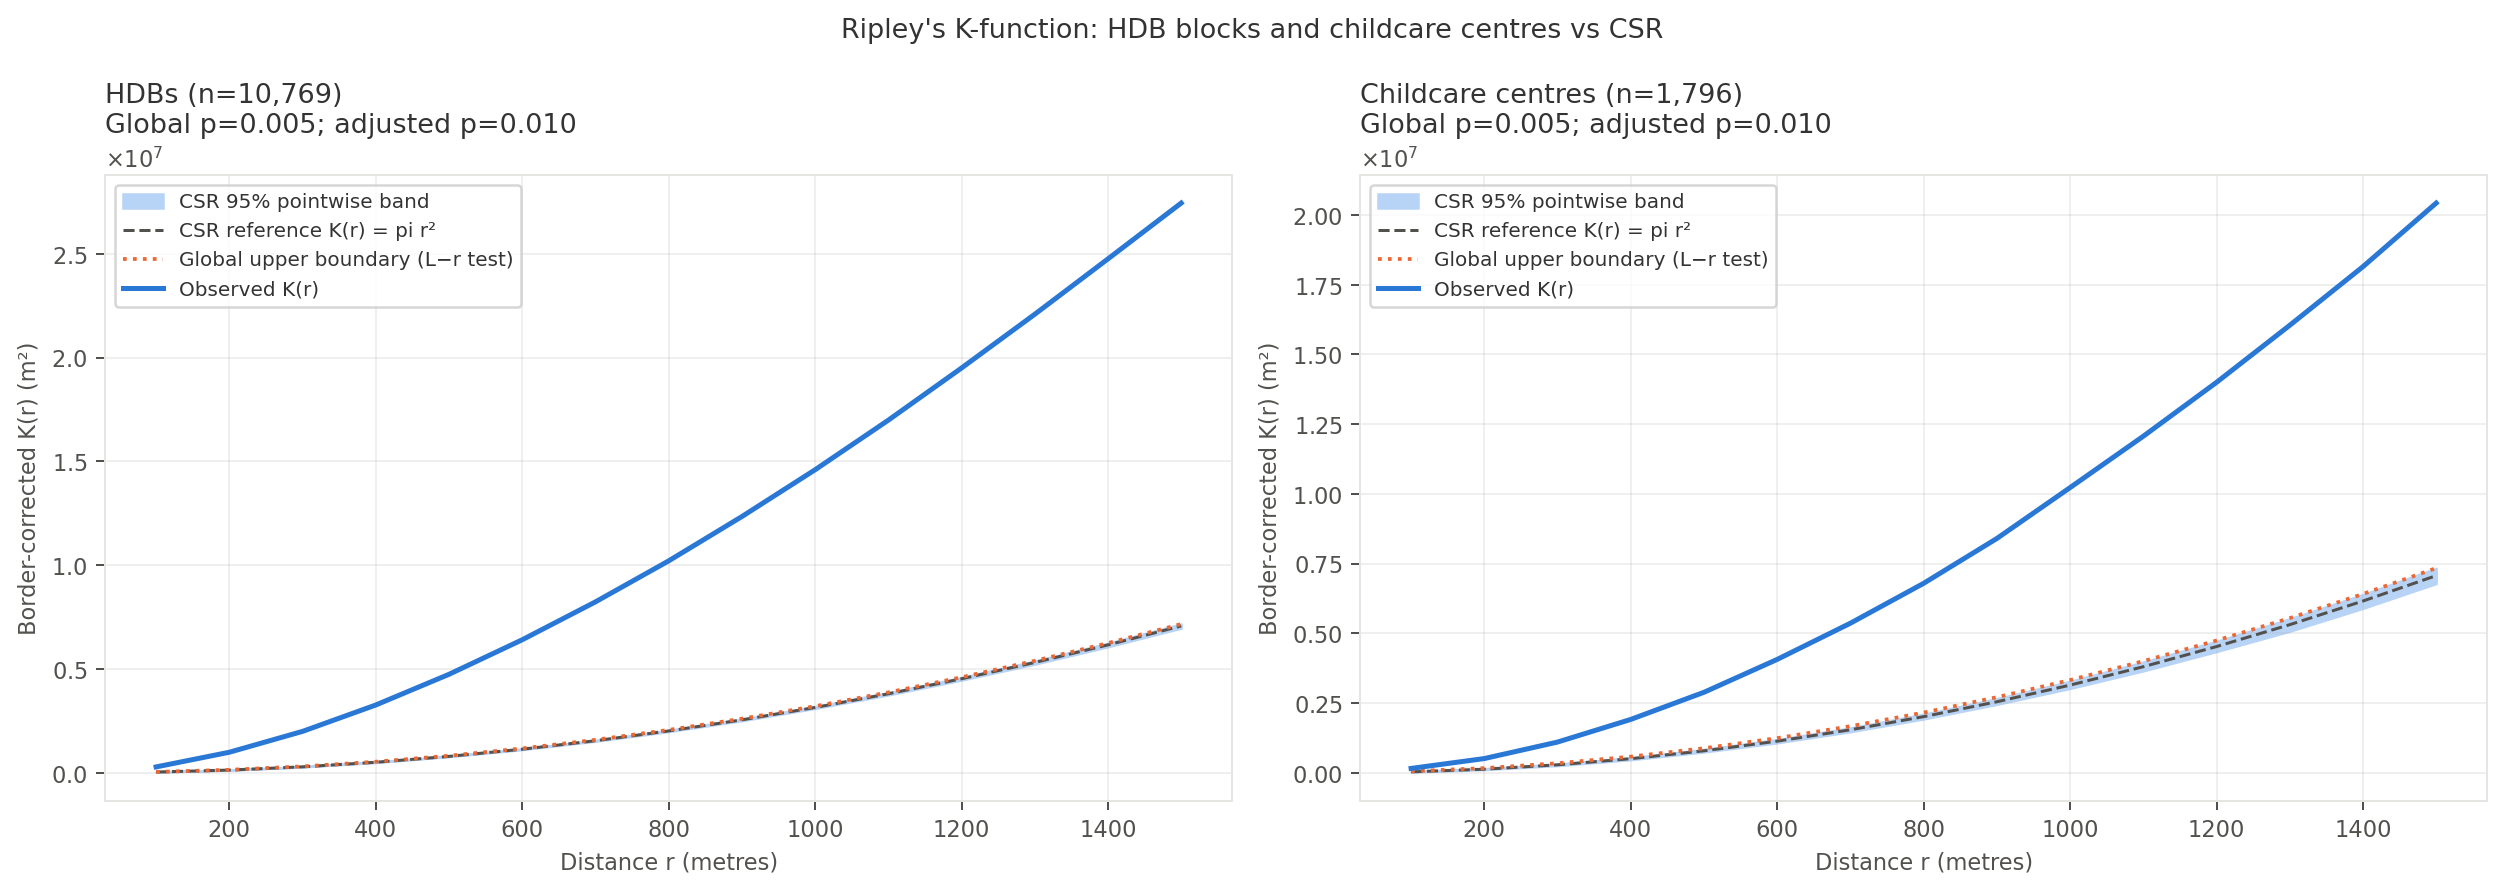

In [5]:
k = pd.read_csv(OUT / "k_function" / "k_summary.csv")
table(k[["pattern", "analysed_n", "max_L_minus_r_m", "global_p", "significant_clustering_5pct"]], "{:,.3f}")
show(OUT / "k_function" / "k_function_comparison.png", 880)

**The second suspect's evidence: income and fees.** Household income clusters in the central region
(Bukit Timah, Tanglin, River Valley, Downtown Core). Median nursery fees are below S$1,000 almost
everywhere except that same central region, where they run above S$2,000. The two maps look alike;
part 3 tests whether that resemblance is real. (`2_01`, `3_01`.)

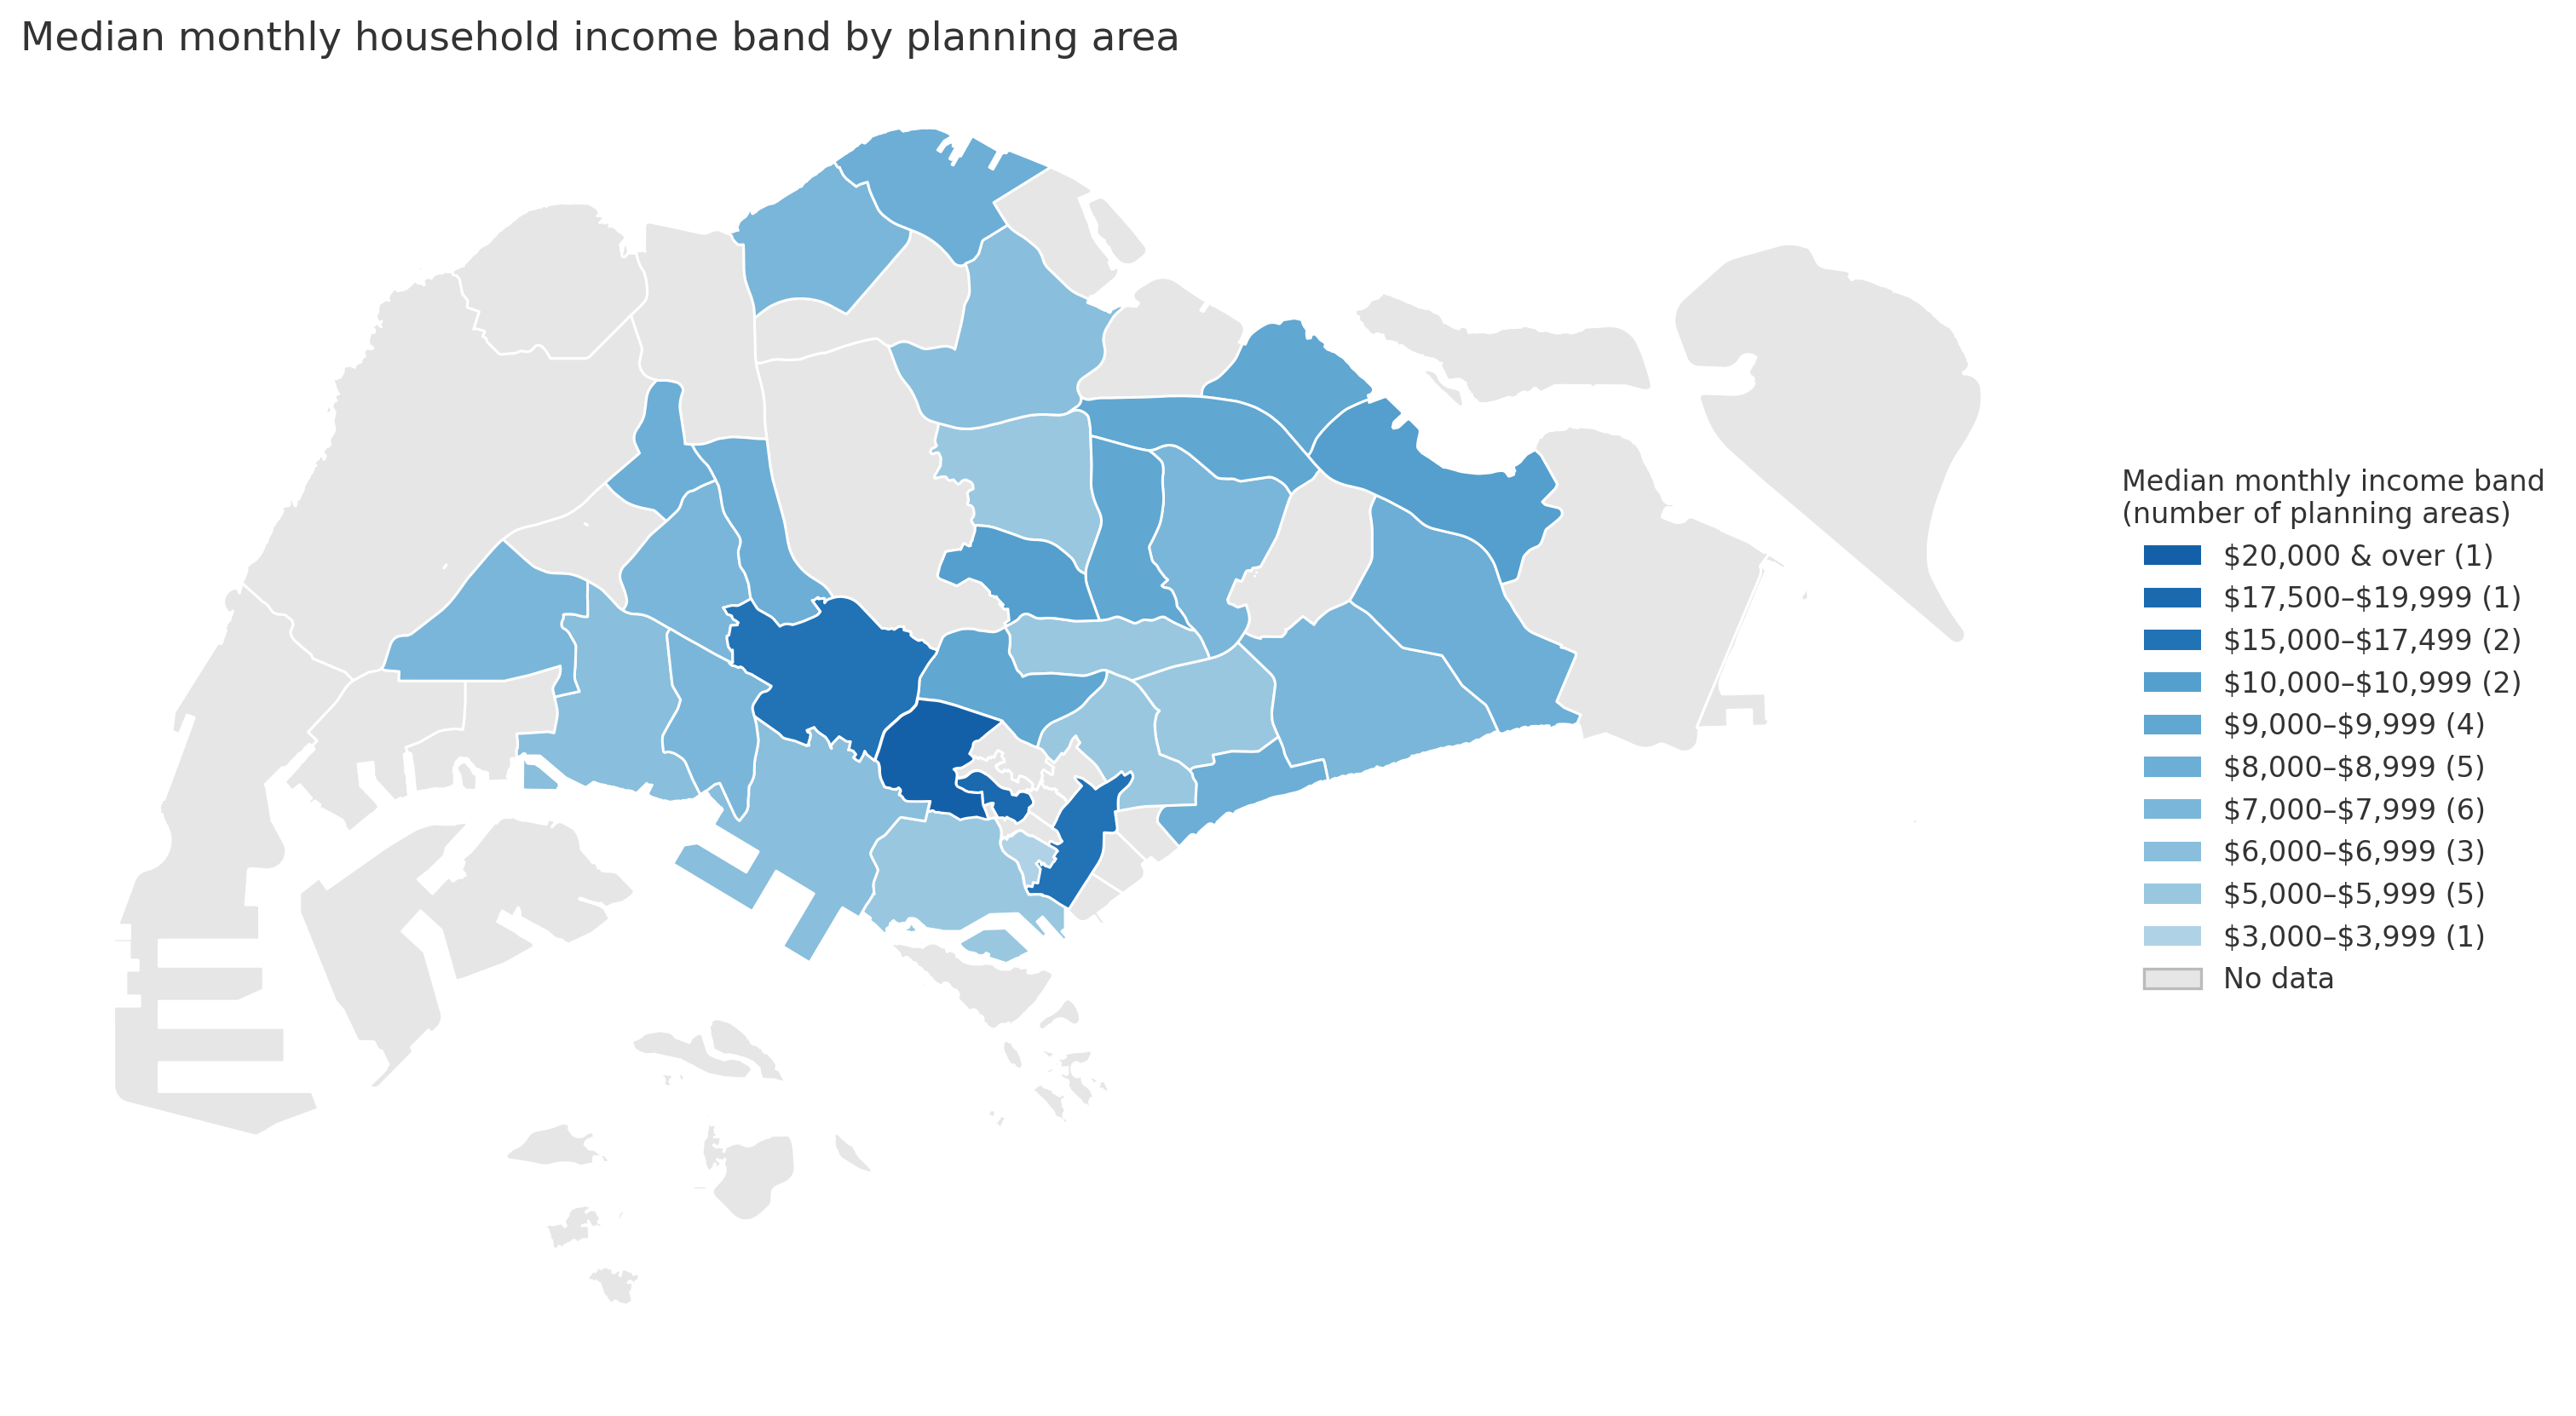

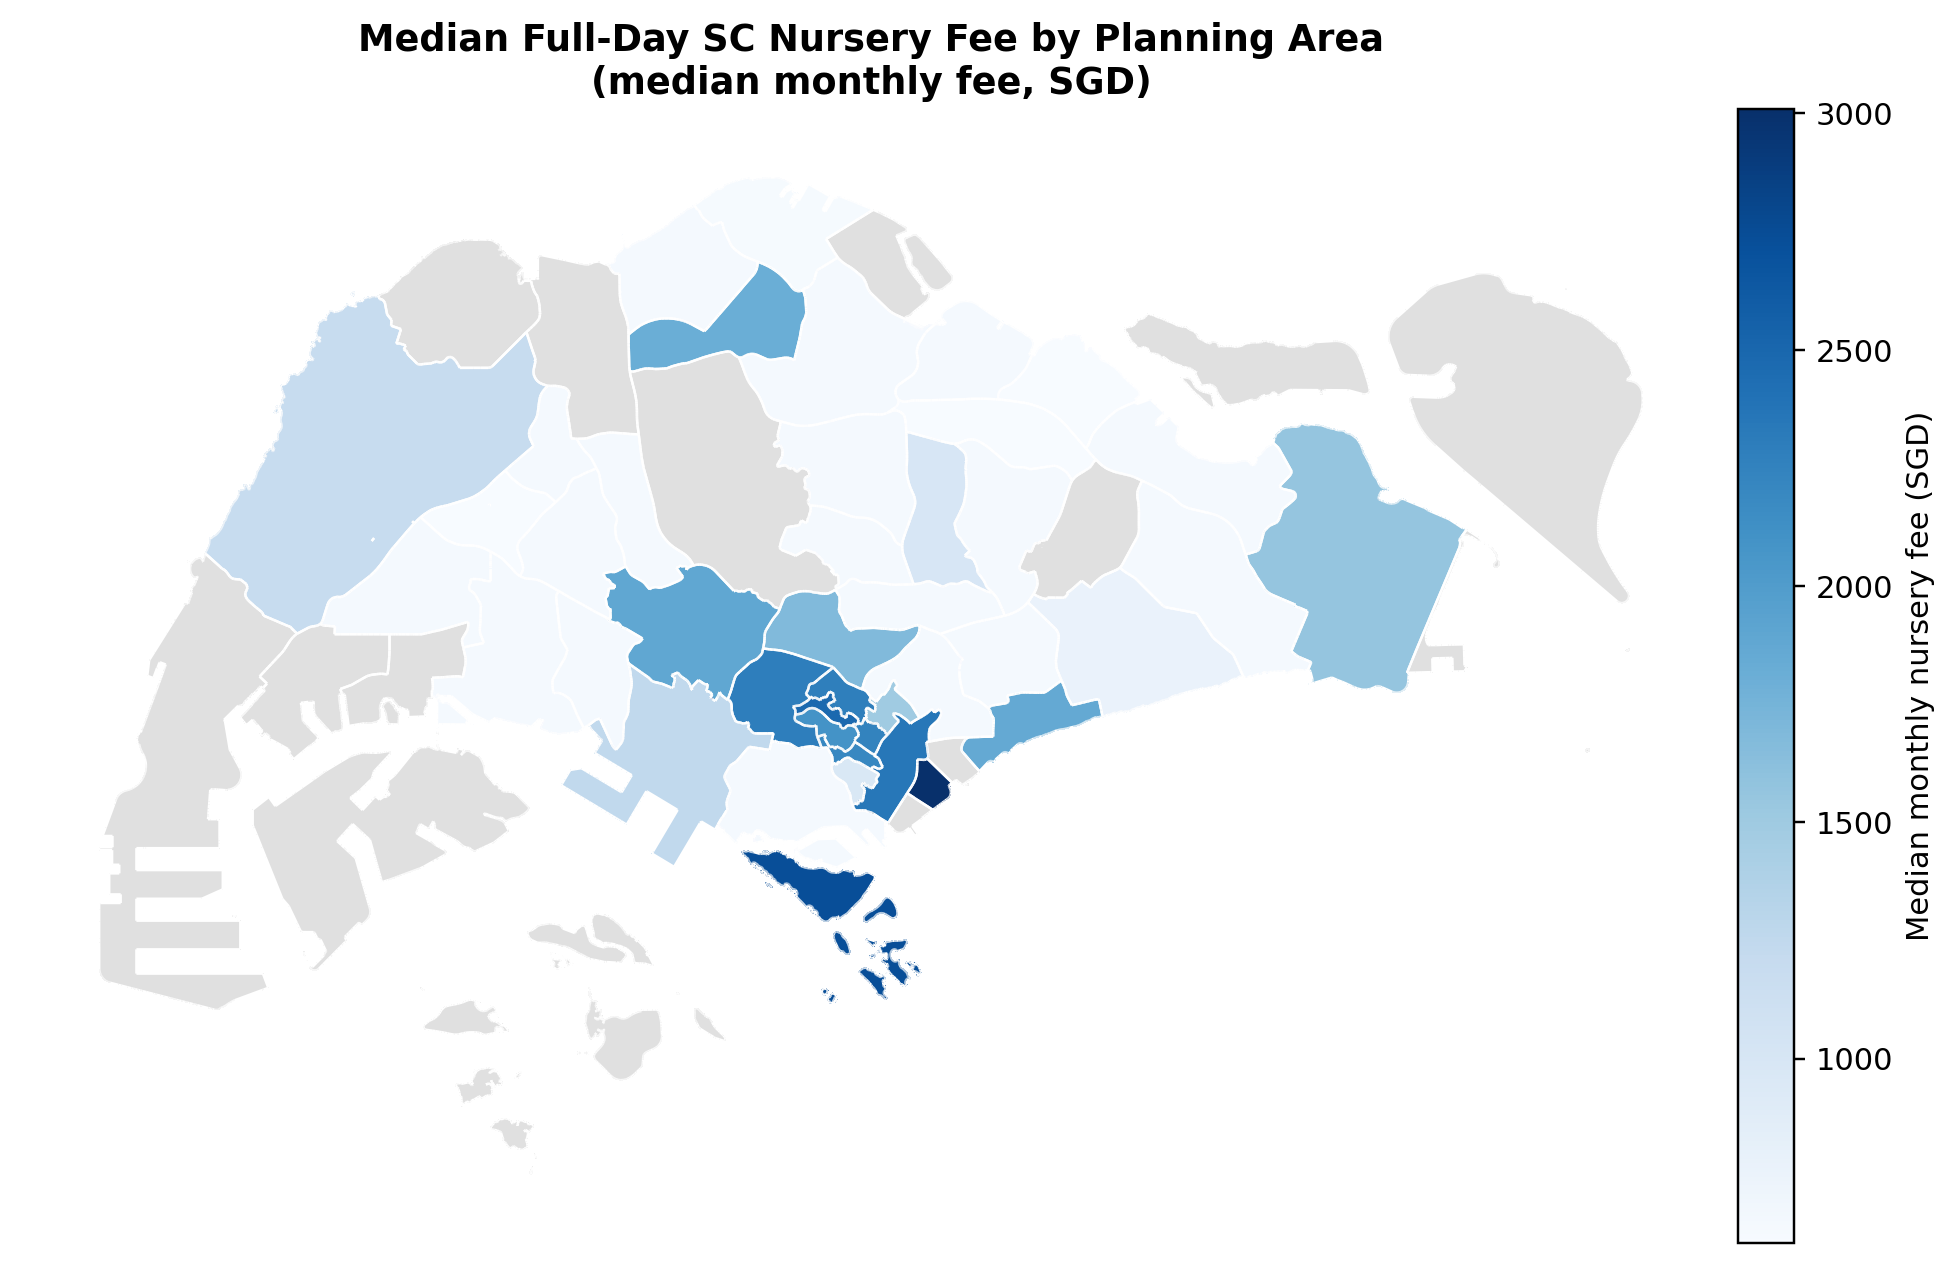

In [6]:
show(OUT / "median_household_income_planning_area" / "median_income_choropleth.png", 820)
show(OUT / "spatial_autocorrelation_nursery_fee_planning_area_2026" / "nursery_fee_choropleth.png", 820)

## 3. Suspect one: price

**Do fees cluster?** Global Moran's I on median full-day nursery fees by planning area, with
4-nearest-neighbour weights and 999 permutations. Then the local version: which areas form the
clusters. (`3_01`.)

Fees are spatially clustered: global Moran's I = 0.511, pseudo-p = 0.001 (42 planning areas with a fee; expected value under randomness -0.024)


lisa_cluster_p05,planning_area,median_fee_sgd,centre_count,local_permutation_p
High-High,MARINA SOUTH,"3,010.000",1.000,0.002
High-High,ORCHARD,"2,480.000",3.000,0.004
High-High,DOWNTOWN CORE,"2,350.000",18.000,0.008
High-High,TANGLIN,"2,291.000",11.000,0.007
High-High,NEWTON,"2,280.000",4.000,0.002
High-High,MUSEUM,"2,250.000",1.000,0.001
High-High,SINGAPORE RIVER,"2,200.000",6.000,0.001
High-High,RIVER VALLEY,"2,100.000",7.000,0.006
High-Low,MANDAI,"1,815.000",2.000,0.041
Low-High,OUTRAM,975.000,8.000,0.001


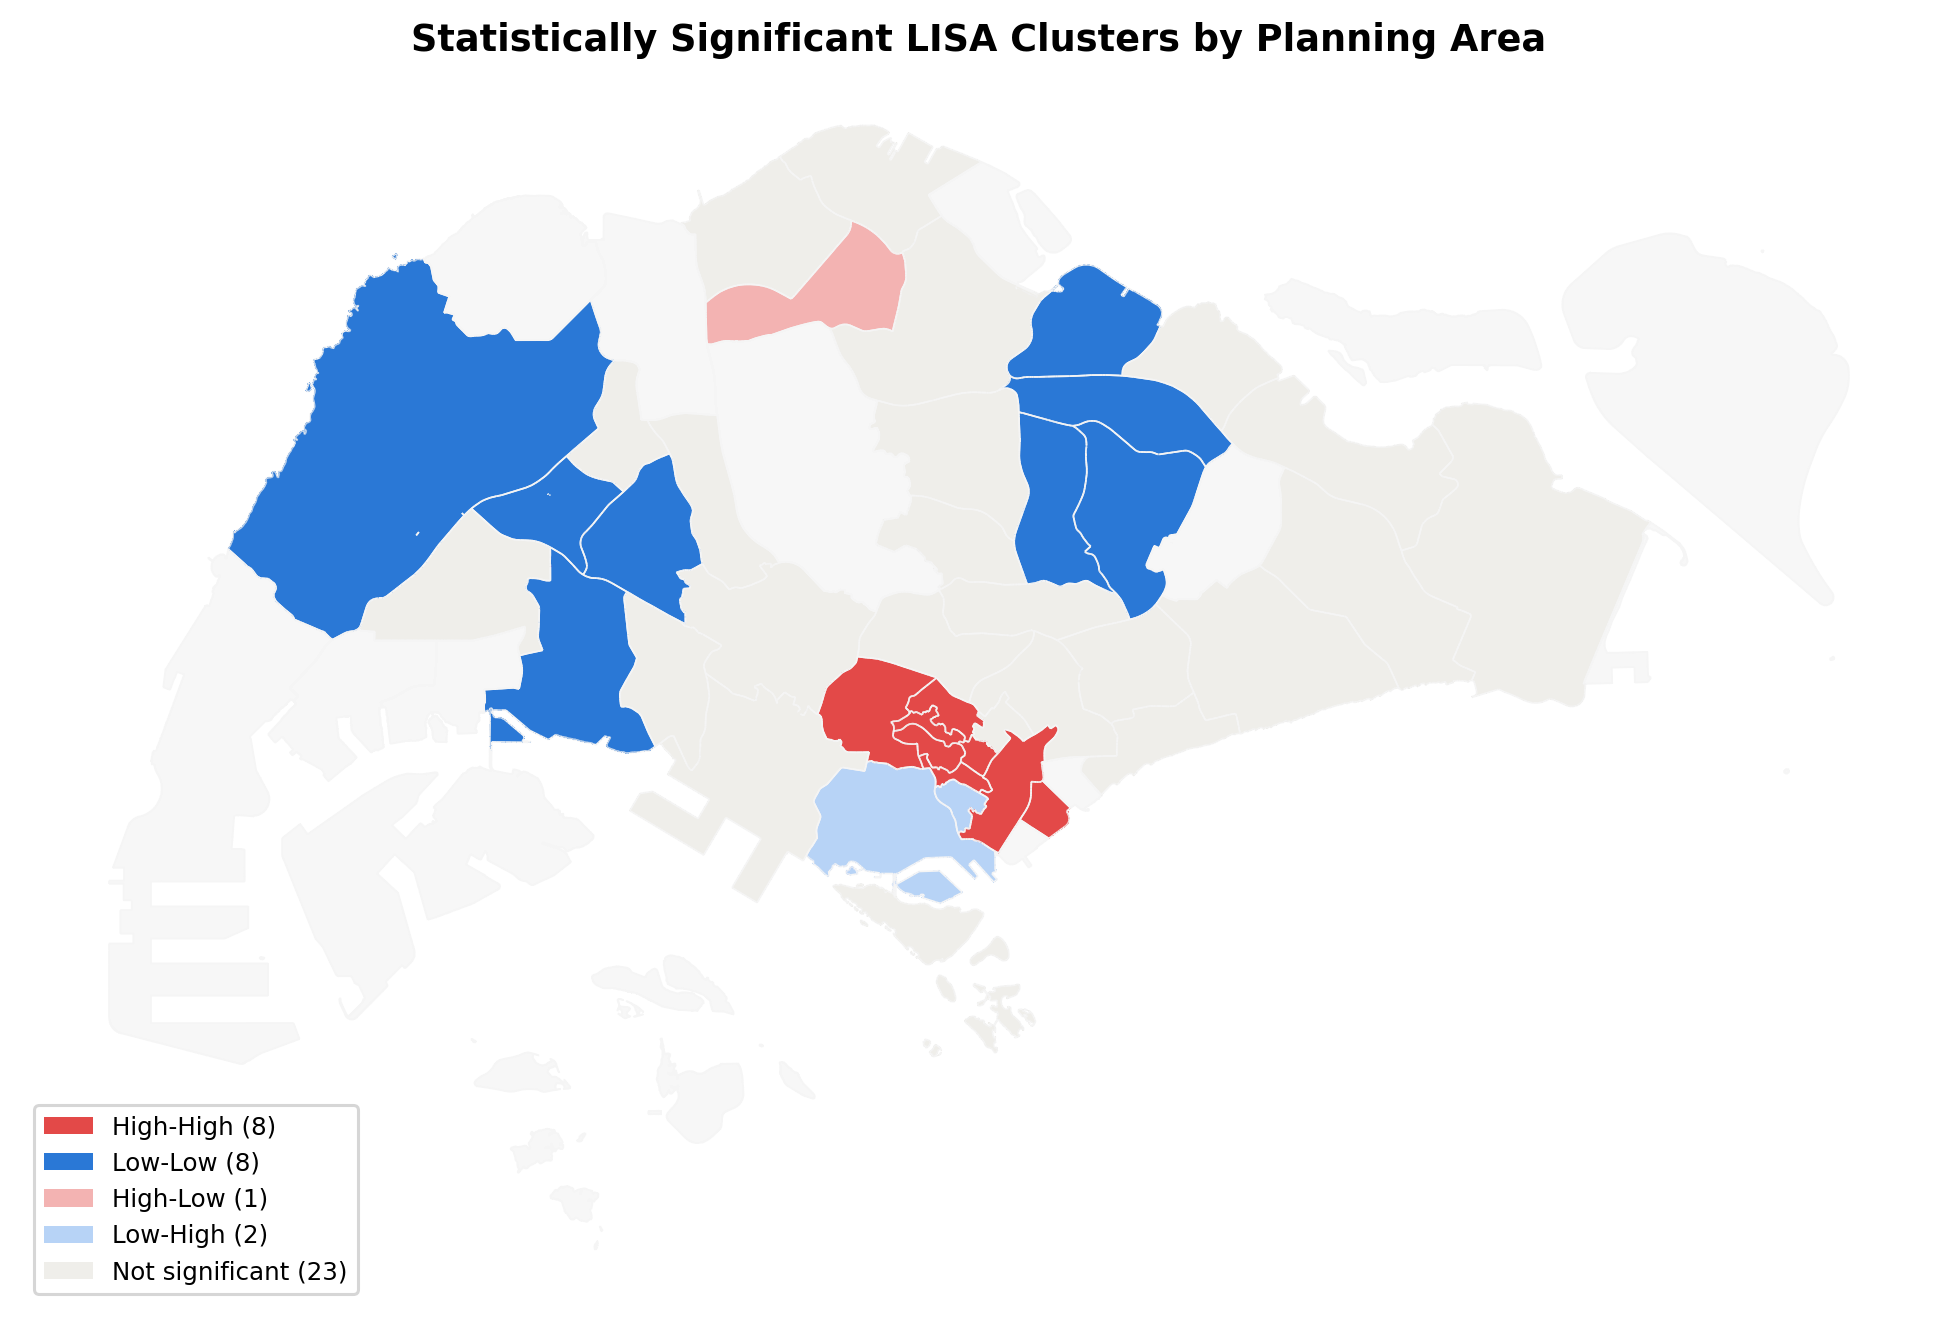

In [7]:
fee_dir = OUT / "spatial_autocorrelation_nursery_fee_planning_area_2026"
fee_I = read_summary_stat(fee_dir / "analysis_summary.md", "Observed I")
fee_p = read_summary_stat(fee_dir / "analysis_summary.md", "Permutation pseudo-p")
fee_pa = pd.read_csv(fee_dir / "planning_area_nursery_fee_moran.csv")
print(f"Fees are spatially clustered: global Moran's I = {fee_I:.3f}, pseudo-p = {fee_p:.3f} "
      f"({len(fee_pa)} planning areas with a fee; expected value under randomness {-1 / (len(fee_pa) - 1):.3f})")

# 1. The significant local clusters, grouped by quadrant: the central high-fee core, the heartland low-fee belt,
#    and the two low-high outliers pressed against the expensive ring.
sig = (fee_pa[fee_pa["lisa_cluster_p05"] != "Not significant"]
       .sort_values(["lisa_cluster_p05", "median_fee_sgd"], ascending=[True, False])
       [["lisa_cluster_p05", "planning_area", "median_fee_sgd", "centre_count", "local_permutation_p"]])
table(sig, "{:,.3f}")
show(fee_dir / "local_moran_lisa_map.png", 820)

Eight central areas (Newton, Orchard, River Valley, Tanglin, Singapore River, Downtown Core, Museum,
Marina South) form one high-high core. The low-low group is heartland towns at the anchor-operator fee.
Outram and Bukit Merah are **low-high outliers**: HDB areas at S$650–975 pressed against the S$2,000
ring, which shows that anchor-operator centres hold the price down even next door to the most expensive
childcare in the country. Keep them in mind for the recommendations.

**Do fees follow income?** OLS of median fee on the estimated median household income of the 30
planning areas that have both. Then a geographically weighted regression lets the slope vary across the
island, and a Monte Carlo test asks whether that variation is more than chance. (`3_02`, `3_03`.)

OLS: fees rise S$113.9 per S$1,000 of median household income (bootstrap 95% CI 70.9 to 142.1); R-squared 0.626; Pearson r 0.79, permutation p 0.00006; n = 30
GWR: 14 neighbours by leave-one-out CV; R-squared 0.861 vs OLS 0.626; AICc 429.2 vs 439.4
     residual Moran's I: OLS 0.27 (p 0.009) -> GWR -0.21
     Monte Carlo test of a spatially varying income slope: p = 0.345 -> no evidence the slope differs across the island


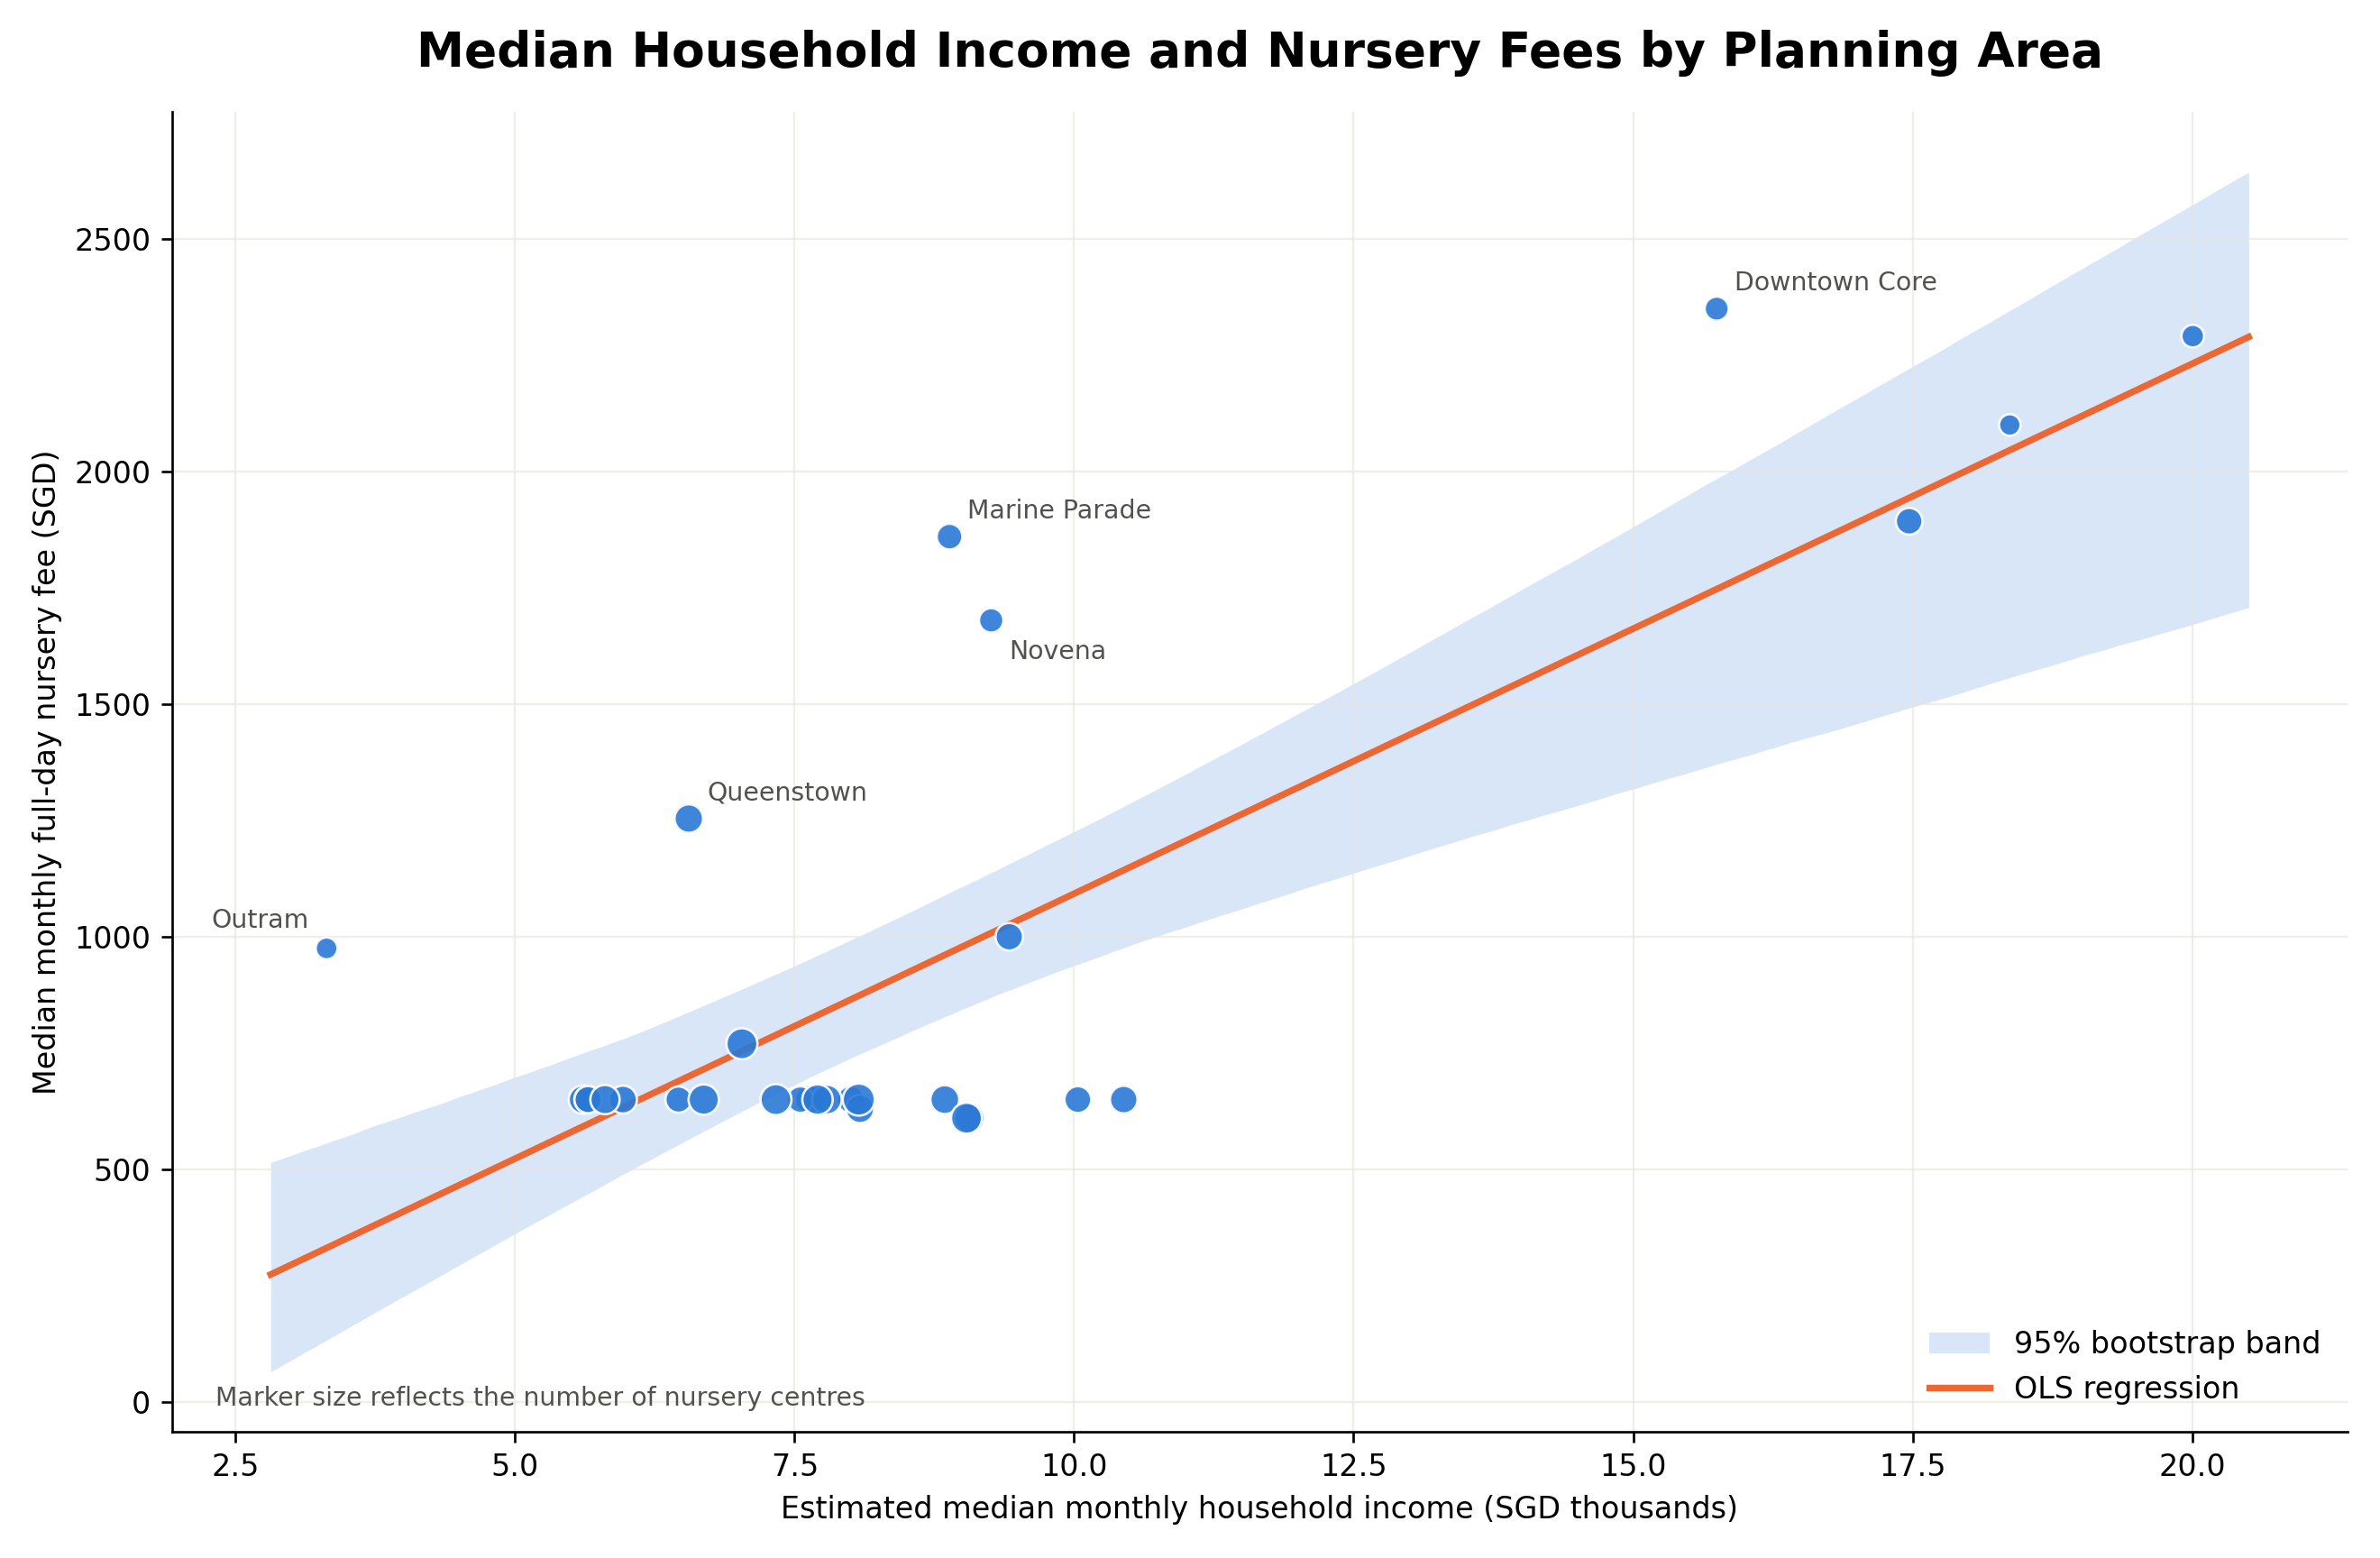

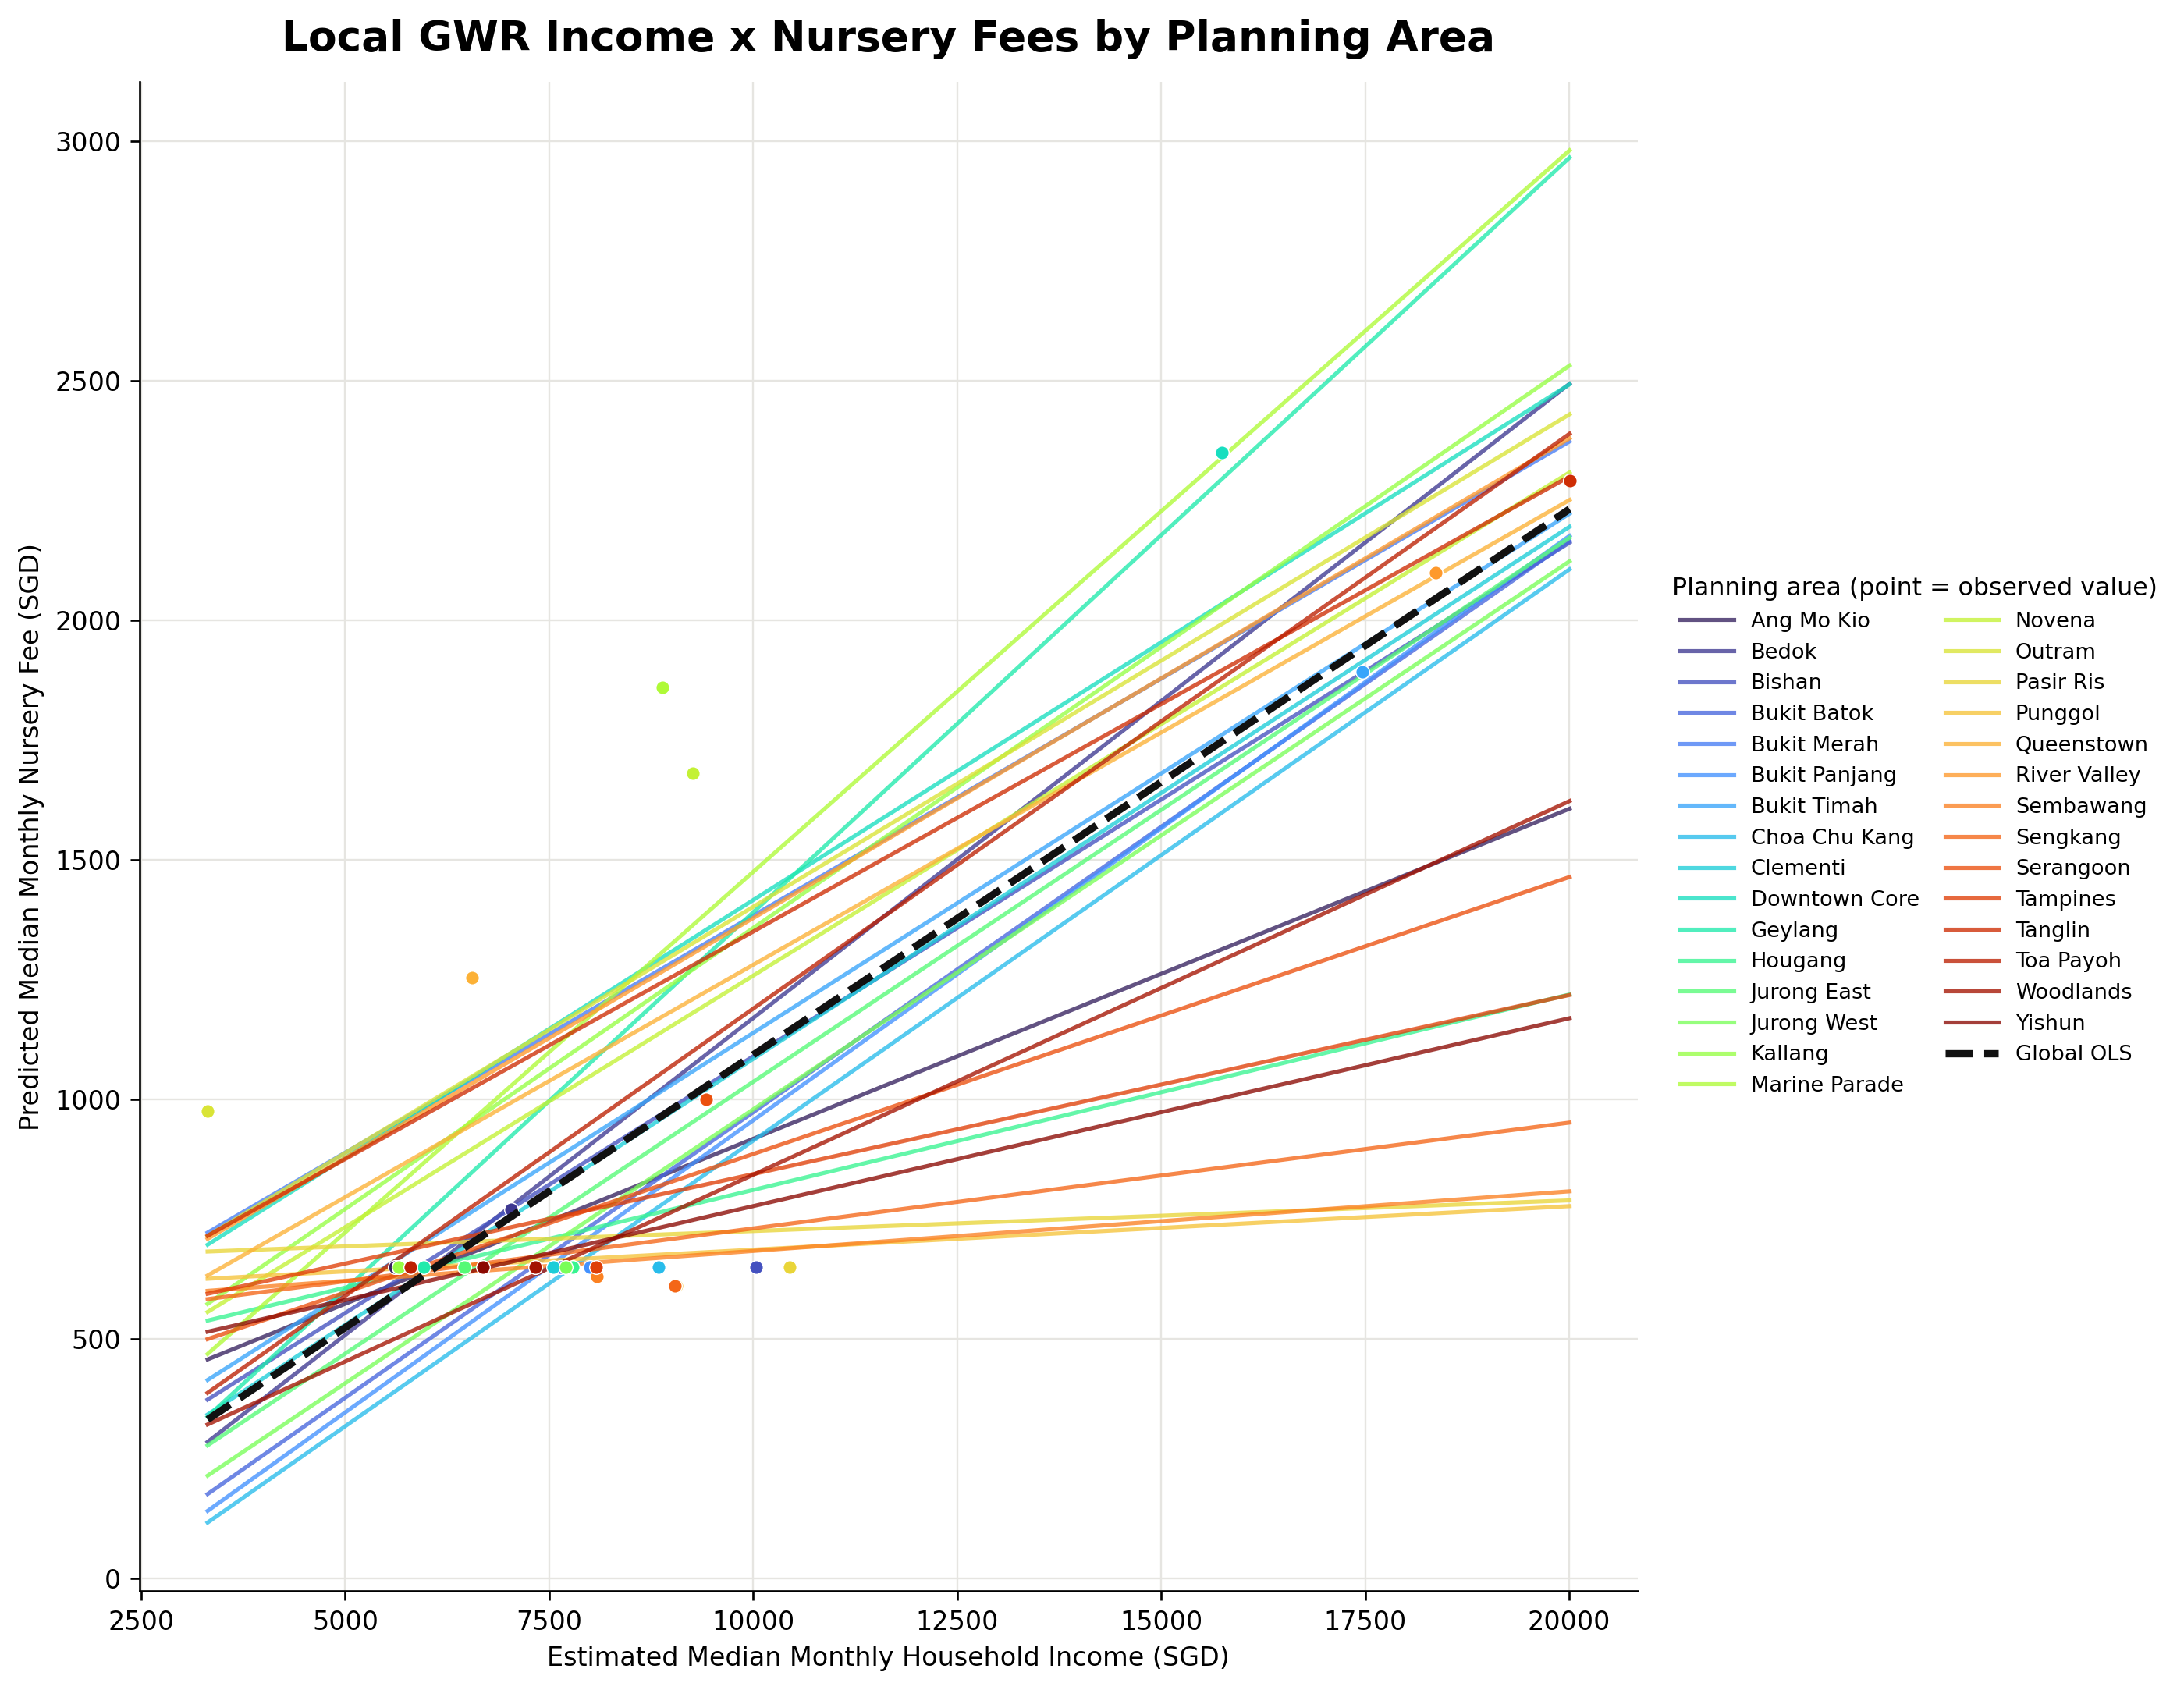

In [8]:
ols = pd.read_csv(OUT / "household_income_nursery_fee_regression_2026" / "regression_summary.csv").set_index("metric")["value"]
gwr = pd.read_csv(OUT / "gwr_income_nursery_fee_planning_area_2026" / "gwr_model_summary.csv").set_index("metric")["value"]
print(f"OLS: fees rise S${ols['slope_sgd_per_1000_income']:.1f} per S$1,000 of median household income "
      f"(bootstrap 95% CI {ols['slope_bootstrap_ci_95_low']:.1f} to {ols['slope_bootstrap_ci_95_high']:.1f}); "
      f"R-squared {ols['r_squared']:.3f}; Pearson r {ols['pearson_r']:.2f}, permutation p {ols['pearson_permutation_p_two_sided']:.5f}; "
      f"n = {ols['matched_planning_areas']:.0f}")
print(f"GWR: {gwr['selected_adaptive_neighbours']:.0f} neighbours by leave-one-out CV; R-squared {gwr['gwr_r_squared']:.3f} vs OLS {gwr['ols_r_squared']:.3f}; "
      f"AICc {gwr['gwr_aicc']:.1f} vs {gwr['ols_aicc']:.1f}")
print(f"     residual Moran's I: OLS {gwr['ols_residual_moran_i']:.2f} (p {gwr['ols_residual_moran_p']:.3f}) -> GWR {gwr['gwr_residual_moran_i']:.2f}")
print(f"     Monte Carlo test of a spatially varying income slope: p = {gwr['monte_carlo_income_slope_variability_p']:.3f} "
      f"-> no evidence the slope differs across the island")
show(OUT / "household_income_nursery_fee_regression_2026" / "income_nursery_fee_regression.png", 760)
show(OUT / "gwr_income_nursery_fee_planning_area_2026" / "gwr_local_regression_lines.png", 880)

**Verdict on price.** Fees cluster strongly and they follow income, about S$114 per S$1,000, with one
national gradient (the GWR fits better in-sample but the Monte Carlo test finds the slope variation is
no larger than random relocation would produce). But the high-fee cluster lives in the central region,
where there are almost no HDB children. For an HDB family, price is real but it is not the suspect.

## 4. Suspect two: distance

Is walking access unequal by income or housing type? Walking time from every HDB block to its nearest
centre on the real network, the 5 / 10 / 15 minute catchments, and the medians by income and
flat-type tercile. (`2_04`, `3_07`.)

median walk to the nearest centre (per block): 3.1 min
blocks within 5 / 10 / 15 min of a centre:    81.3% / 99.7% / 99.97%
children 0-6 within 5 / 10 min of a centre:    84.4% / 99.8%
children 0-6 with no centre within 10 min:     332  (blocks: 33, in WOODLANDS WEST, ANAK BUKIT, BEDOK NORTH, CHANGI POINT, BEDOK SOUTH, YISHUN WEST, PASIR RIS WEST, KEMBANGAN, PASIR RIS CENTRAL, ALEXANDRA HILL)

median subzone walk time (min) by tercile:
      by planning-area income  by share of 1-3-room flats
low                       3.3                         3.0
mid                       3.4                         3.2
high                      2.9                         3.3


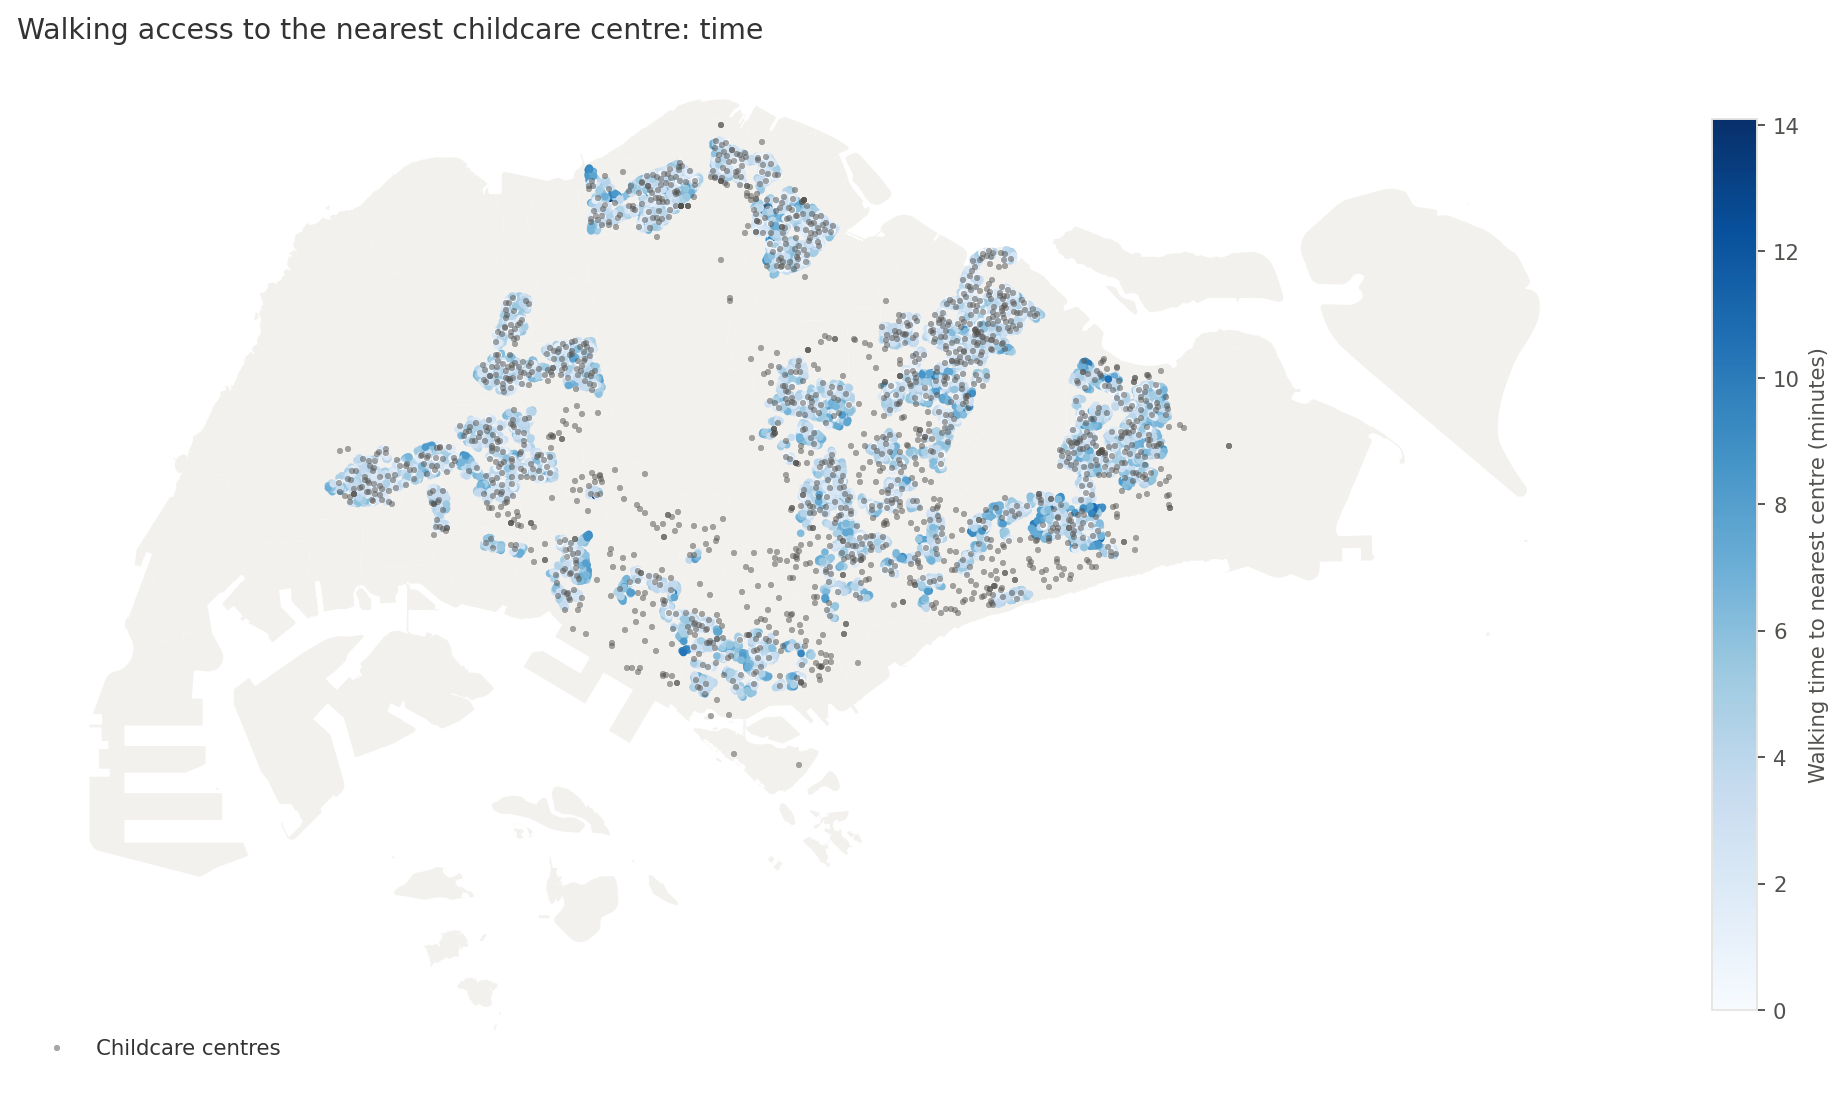

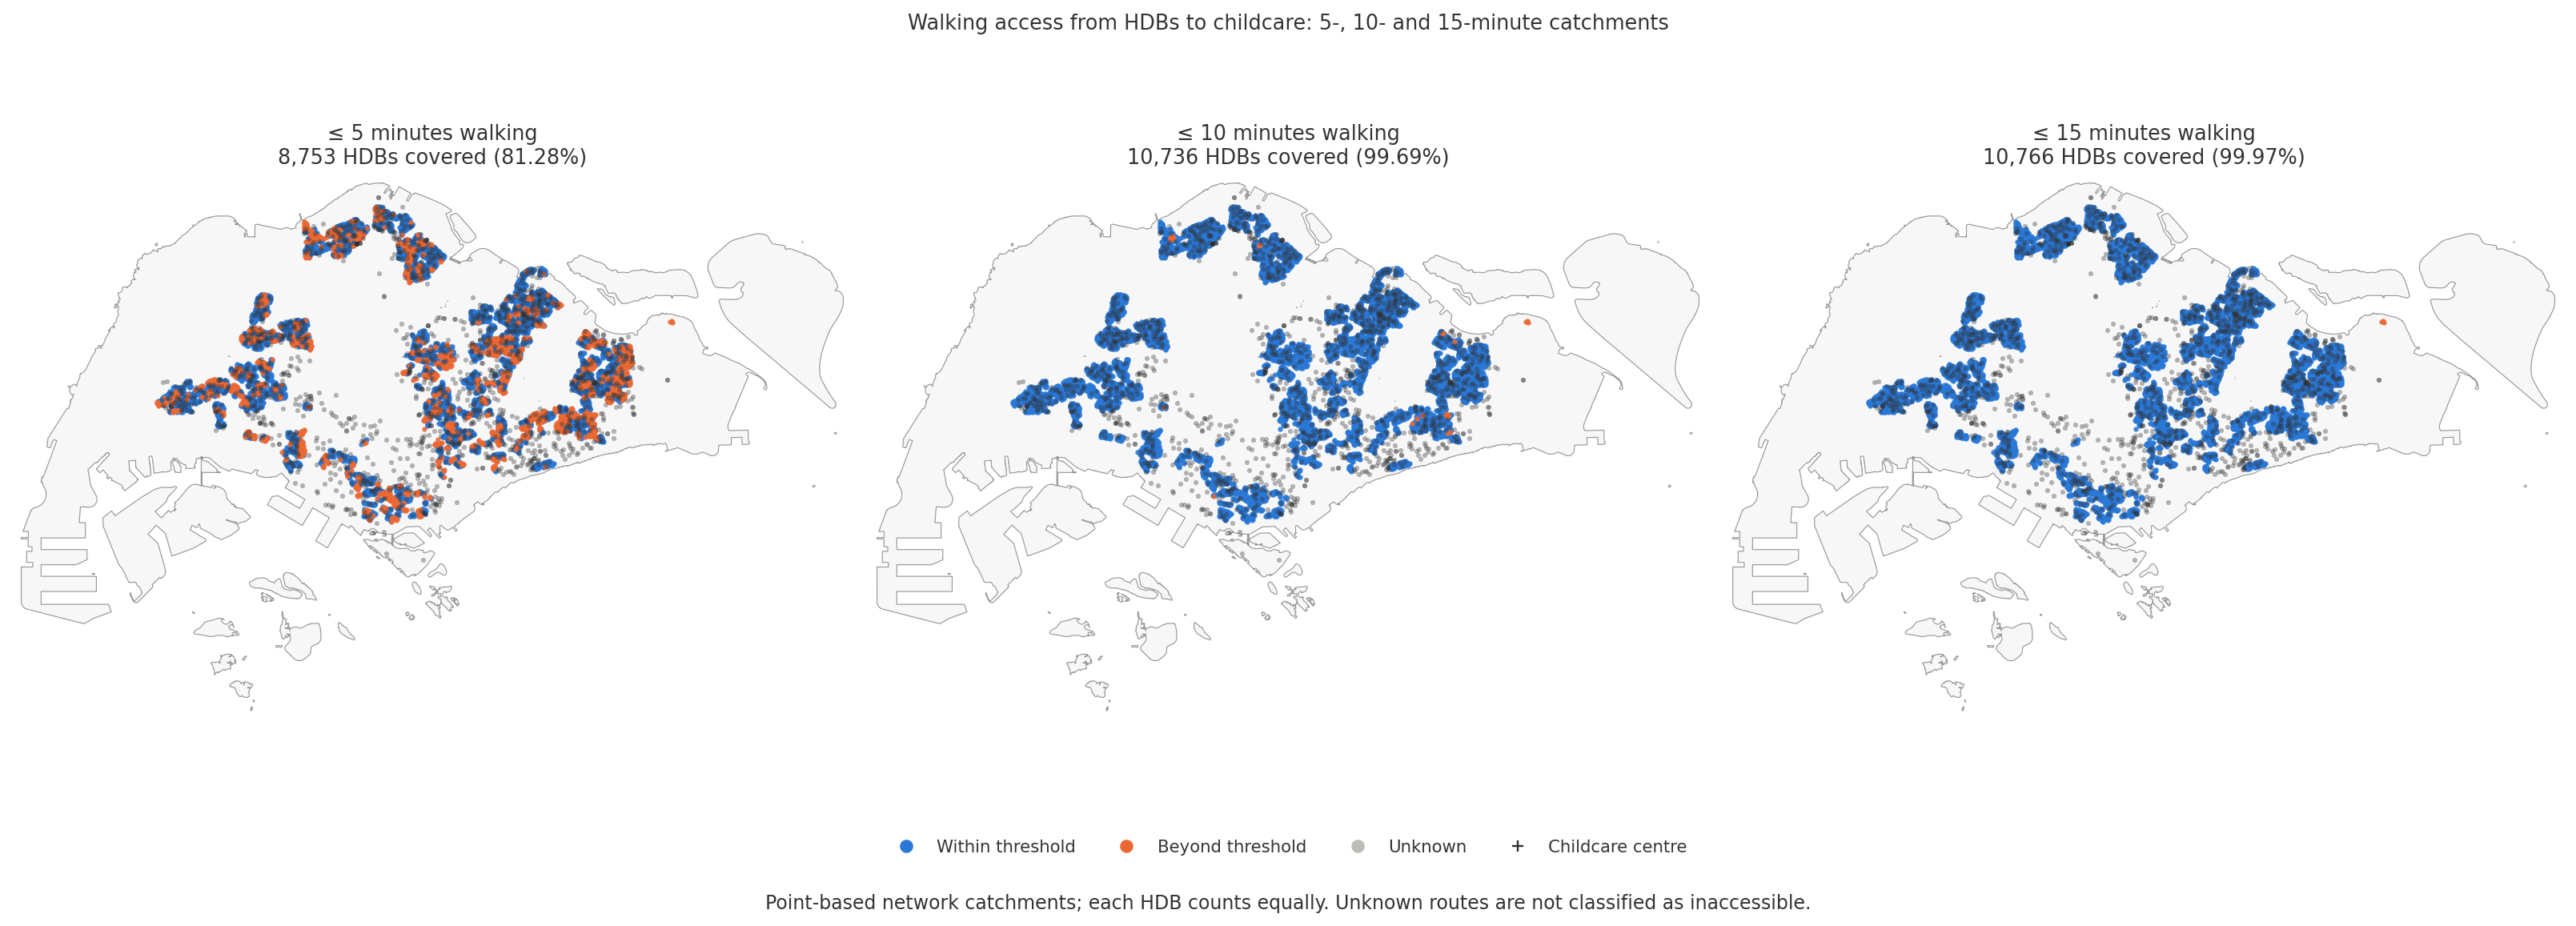

In [9]:
w = blocks["child_0_6"]
within = lambda minutes: (w[blocks["centres_nearest_min"] <= minutes].sum() / w.sum())
no_centre_10 = w[blocks["has_centre_10min"] == 0].sum()
print(f"median walk to the nearest centre (per block): {blocks['centres_nearest_min'].median():.1f} min")
print(f"blocks within 5 / 10 / 15 min of a centre:    "
      f"{(blocks['centres_nearest_min'] <= 5).mean():.1%} / {(blocks['centres_nearest_min'] <= 10).mean():.1%} / "
      f"{(blocks['centres_nearest_min'] <= 15).mean():.2%}")
print(f"children 0-6 within 5 / 10 min of a centre:    {within(5):.1%} / {within(10):.1%}")
print(f"children 0-6 with no centre within 10 min:     {no_centre_10:,.0f}  "
      f"(blocks: {int((blocks['has_centre_10min'] == 0).sum())}, in {', '.join(blocks.loc[blocks['has_centre_10min'] == 0, 'SUBZONE_N'].unique())})")

# 1. Does the walk differ by SES? Subzone child-weighted walk time, by tercile of planning-area income and of the
#    share of 1-3-room flats (the only SES measures that exist at subzone level; income is planning-area only).
sz = subzones[subzones["has_hdb"] == 1].copy()
sz["income tercile"] = pd.qcut(sz["pa_median_income_sgd"], 3, labels=["low", "mid", "high"])
sz["1-3-room tercile"] = pd.qcut(sz["pct_1to3room"], 3, labels=["few", "mid", "many"])
by_ses = pd.DataFrame({
    "by planning-area income": sz.groupby("income tercile", observed=True)["walk_nearest_min_cw"].median(),
    "by share of 1-3-room flats": sz.groupby("1-3-room tercile", observed=True)["walk_nearest_min_cw"].median().set_axis(["low", "mid", "high"]),
})
print("\nmedian subzone walk time (min) by tercile:")
print(by_ses.round(1).to_string())
show(FIG / "walk_nearest_time_map.png", 820)
show(FIG / "walk_catchments_5_10_15.png", 880)

**Verdict on distance.** The median walk is about three minutes; four in five children live within five
minutes of a centre and practically all within ten. The only children with no centre within a ten-minute
walk are a few hundred in the Changi Village flats. Across income and flat-type terciles the median walk
barely moves (`3_07` tests this formally: Spearman near zero, differences of about twenty seconds).
Distance is cleared.

That leaves the pivot of the whole project: **if every family can walk to a centre, access is about
crowding.** The question becomes how many children each centre has to serve.

## 5. The instrument: supply pressure

Two-step floating catchment area (2SFCA) on the walk matrix, in three steps:

1. For each centre, count the children within a ten-minute walk. That is its **pool**.
2. For each block, add up one over the pool of every centre it can reach. That is its access.
3. Flip it: **pressure = children per reachable centre.** Aggregate to subzones weighting by children.

Every centre counts as one unit (capacity is not published), so this measures how thinly the centres
nearby are spread across the children nearby. (`3_06`.)

median subzone pressure: 106 children per reachable centre (p10 54, p90 177; 140 subzones with >= 100 children)


SUBZONE_N,PLN_AREA_N,children_0_6,centres_n,walk_nearest_min_cw,pressure_base
PLANTATION,TENGAH,"1,960",4,3,345
SERANGOON CENTRAL,SERANGOON,493,8,4,39


Plantation's queue is 9x Serangoon Central's


SUBZONE_N,PLN_AREA_N,children_0_6,centres_n,pressure_base,lisa_q
TAMPINES NORTH,TAMPINES,"6,838",10,596,ns
GARDEN,TENGAH,"1,204",5,361,HH
PLANTATION,TENGAH,"1,960",4,345,HH
PARK,TENGAH,"1,230",5,318,HH
GOMBAK,BUKIT BATOK,223,4,309,ns
SEMBAWANG EAST,SEMBAWANG,"2,336",9,246,ns
WOODLANDS WEST,WOODLANDS,"2,206",8,241,ns
BRICKWORKS,BUKIT BATOK,"3,741",12,222,HH
NORTHSHORE,PUNGGOL,"3,271",16,204,ns
MATILDA,PUNGGOL,"3,565",14,197,HH


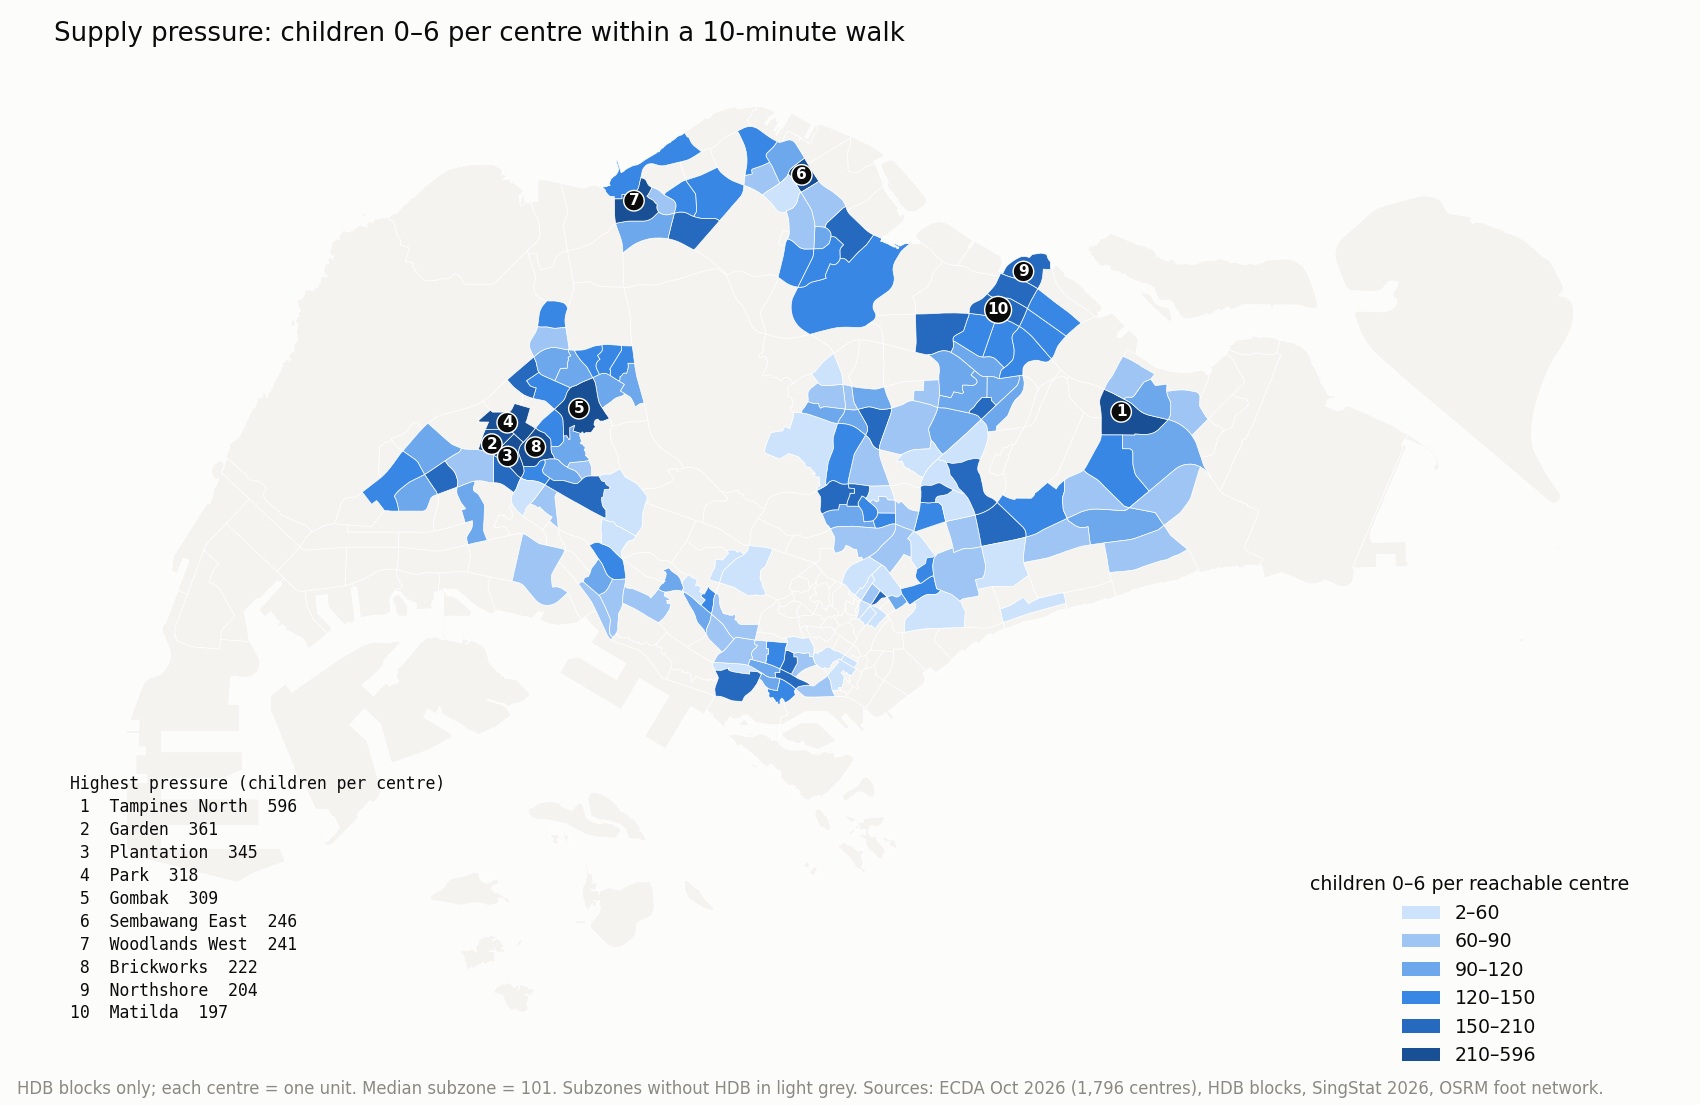

In [10]:
sp = pd.read_csv(OUT / "subzone_pressure.csv")
sp = sp[(sp["has_hdb"] == 1) & (sp["children_0_6"] >= 100)]   # the 140 subzones the LISA tests, as on the deck
print(f"median subzone pressure: {sp['pressure_base'].median():.0f} children per reachable centre "
      f"(p10 {sp['pressure_base'].quantile(.1):.0f}, p90 {sp['pressure_base'].quantile(.9):.0f}; {len(sp)} subzones with >= 100 children)")

# 1. One family, two estates: same walk, very different queue.
pair = sp[sp["SUBZONE_N"].isin(["PLANTATION", "SERANGOON CENTRAL"])][
    ["SUBZONE_N", "PLN_AREA_N", "children_0_6", "centres_n", "walk_nearest_min_cw", "pressure_base"]]
table(pair.sort_values("pressure_base", ascending=False), "{:,.0f}")
print(f"Plantation's queue is {pair.set_index('SUBZONE_N').loc['PLANTATION', 'pressure_base'] / pair.set_index('SUBZONE_N').loc['SERANGOON CENTRAL', 'pressure_base']:.0f}x Serangoon Central's")

# 2. The ten highest-pressure subzones.
top = sp.nlargest(10, "pressure_base")[["SUBZONE_N", "PLN_AREA_N", "children_0_6", "centres_n", "pressure_base", "lisa_q"]]
table(top, "{:,.0f}")
show(FIG / "pressure_map.png", 880)

A high number on its own could be a one-off. **Where does high pressure sit beside high pressure?** Local
Moran's I on log pressure across the 140 HDB subzones with at least 100 children, Queen contiguity with
the two islands attached to their nearest neighbour, 9,999 permutations. Red is a stressed subzone
surrounded by stressed subzones.

global Moran's I on log pressure = 0.176, p = 0.0018 (140 subzones); high-high cluster: 10 subzones


PLN_AREA_N,SUBZONE_N,children_0_6,centres_n,pressure_base,median_fee_listed,lisa_p
BUKIT BATOK,BRICKWORKS,"3,741",12,222,610,0
BUKIT BATOK,HONG KAH NORTH,896,8,123,650,0
JURONG EAST,YUHUA WEST,492,2,175,755,0
PUNGGOL,MATILDA,"3,565",14,197,630,0
PUNGGOL,PUNGGOL TOWN CENTRE,"1,664",15,151,610,0
PUNGGOL,WATERWAY EAST,"3,879",24,145,610,0
TENGAH,GARDEN,"1,204",5,361,610,0
TENGAH,PLANTATION,"1,960",4,345,610,0
TENGAH,PARK,"1,230",5,318,610,0
WOODLANDS,WOODGROVE,"1,369",13,104,650,0


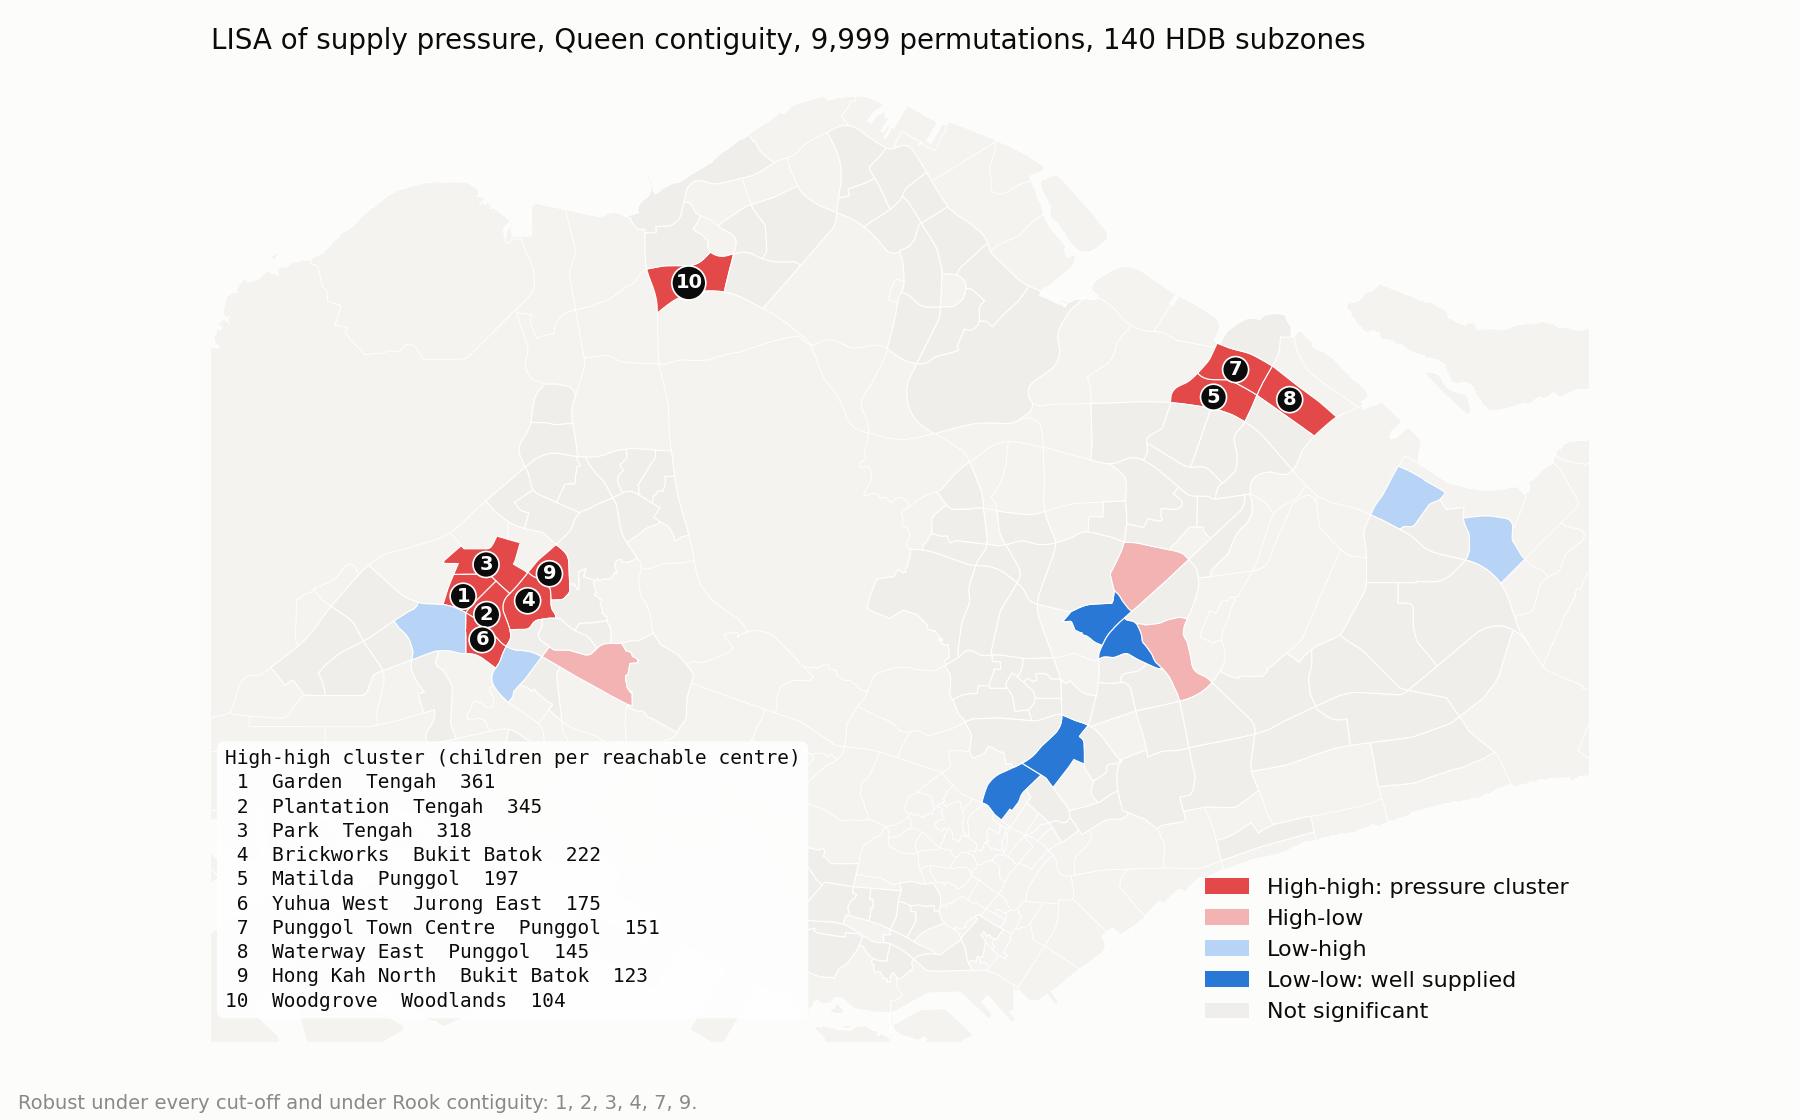

sensitivity to the minimum-children cut-off:
 min_children_0_6  n_subzones  morans_I  p_sim  n_HH
                0         157     0.354 0.0001    13
               50         150     0.205 0.0005    10
              100         140     0.176 0.0018    10
              200         133     0.202 0.0013     7


In [11]:
sens = pd.read_csv(OUT / "lisa_threshold_sensitivity.csv")
base = sens[sens["min_children_0_6"] == 100].iloc[0]
print(f"global Moran's I on log pressure = {base['morans_I']:.3f}, p = {base['p_sim']:.4f} "
      f"({base['n_subzones']} subzones); high-high cluster: {base['n_HH']} subzones")

# 1. The high-high subzones, grouped by town, with their listed fee (this matters for the verdict).
hh = sp[sp["lisa_q"] == "HH"].sort_values(["PLN_AREA_N", "pressure_base"], ascending=[True, False])[
    ["PLN_AREA_N", "SUBZONE_N", "children_0_6", "centres_n", "pressure_base", "median_fee_listed", "lisa_p"]]
table(hh, "{:,.0f}")
show(FIG / "lisa_pressure_zoom.png", 880)

# 2. Robustness: the same test at other minimum-children cut-offs (and Rook contiguity, in 3_06).
print("sensitivity to the minimum-children cut-off:")
print(sens[["min_children_0_6", "n_subzones", "morans_I", "p_sim", "n_HH"]].to_string(index=False))

Ten subzones come out red, in three groups with three different causes:

- **Tengah** (Garden, Plantation, Park): a new town where families moved in before the centres.
- **Bukit Batok and Jurong East** (Brickworks, Hong Kah North, Yuhua West): older estates with few
  centres per child.
- **Punggol** (Matilda, Punggol Town Centre, Waterway East): a mature new town where fourteen to
  twenty-four centres per subzone still cannot keep up.

Plus Woodgrove in Woodlands. Six of the ten stay red under every cut-off and under Rook contiguity
(`figures/lisa_robustness.png`). Tampines North, the single highest value on the map, is not a cluster
because its neighbours are average: the LISA finds clusters, the ranked table finds peaks, and the
recommendations use both.

## 6. The witness: ECDA's own pipeline

ECDA has thirteen centres in the pipeline, and ECDA never saw our index. Where did they put them?
Left, where pressure clusters. Right, where ECDA is building, each dot sized by the children within a
ten-minute walk of it. (`3_08`.)

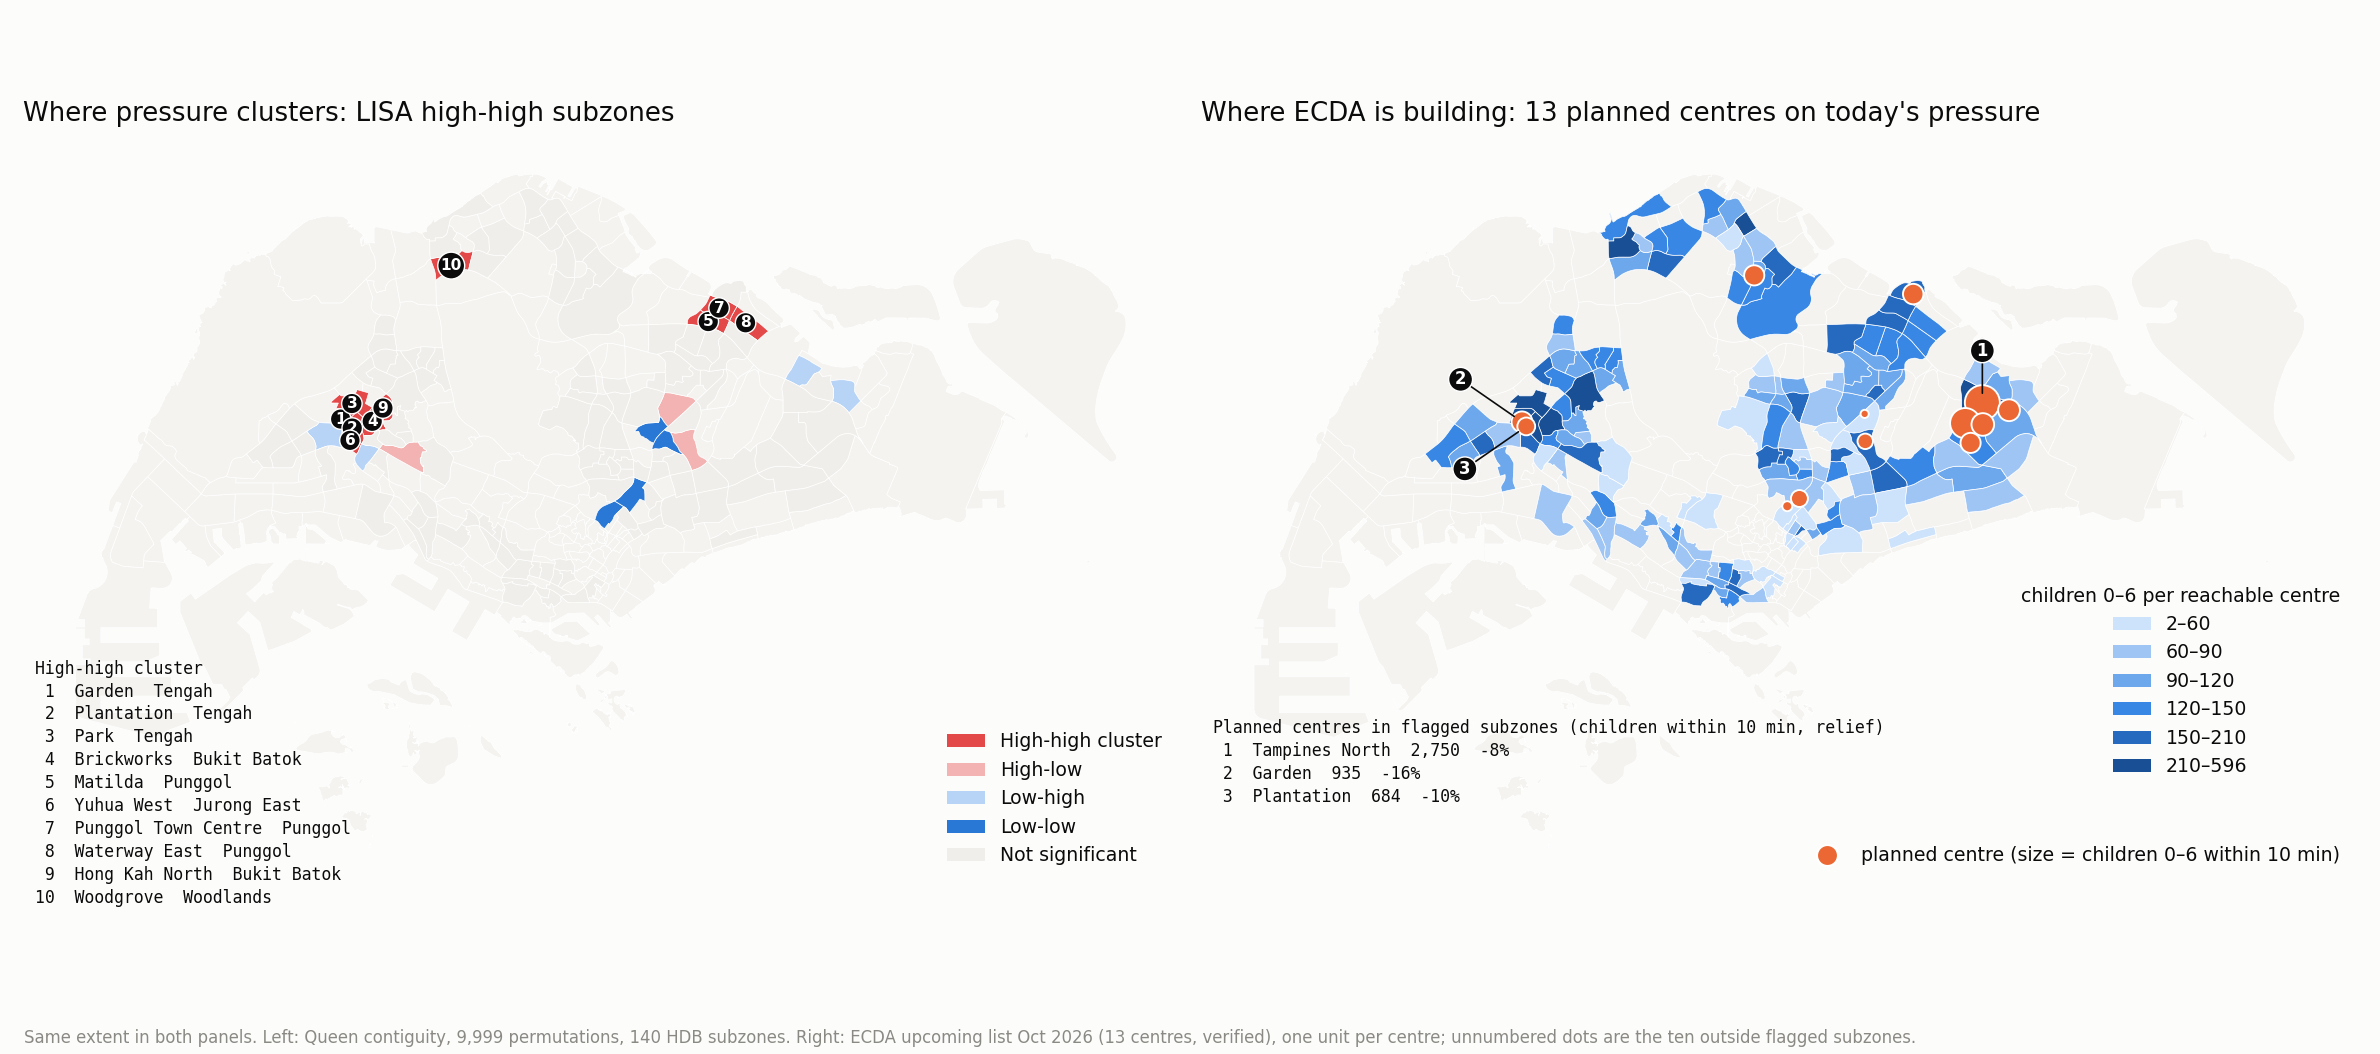

tp_code,centre,SUBZONE_N,PLN_AREA_N,pool_children_0_6,pool_percentile_vs_existing,own_subzone_pressure_before,own_subzone_pct_change
TP0639,PCF Sparkletots Preschool @ Geylang Serai Blk 18,TAI SENG,HOUGANG,516,34,151,-22
TP1051,MY FIRST SKOOL,GARDEN,TENGAH,935,60,361,-16
TP0658,(unnamed ECDA entry),KAMPONG JAVA,KALLANG,216,15,40,-14
TP1433,PCF Sparkletots Preschool @ Tengah Blk 135 (CC),PLANTATION,TENGAH,684,44,345,-10
TP0977,MY FIRST SKOOL,YISHUN CENTRAL,YISHUN,879,57,94,-10
TP1345,PCF SPARKLETOTS PRESCHOOL @ TAMPINES BOULEVARD,TAMPINES NORTH,TAMPINES,"2,750",98,596,-8
TP0777,E-Bridge Pre-School Punggol Digital District,NORTHSHORE,PUNGGOL,903,59,204,-6
TP0641,MY WORLD PRESCHOOL LTD.,LORONG AH SOO,HOUGANG,115,10,30,-5
TP0657,MY FIRST SKOOL,BENDEMEER,KALLANG,619,41,67,-3
TP1348,(unnamed ECDA entry),TAMPINES WEST,TAMPINES,872,57,129,-2


for scale, an existing centre's pool: median 643 children, 90th percentile 1,892


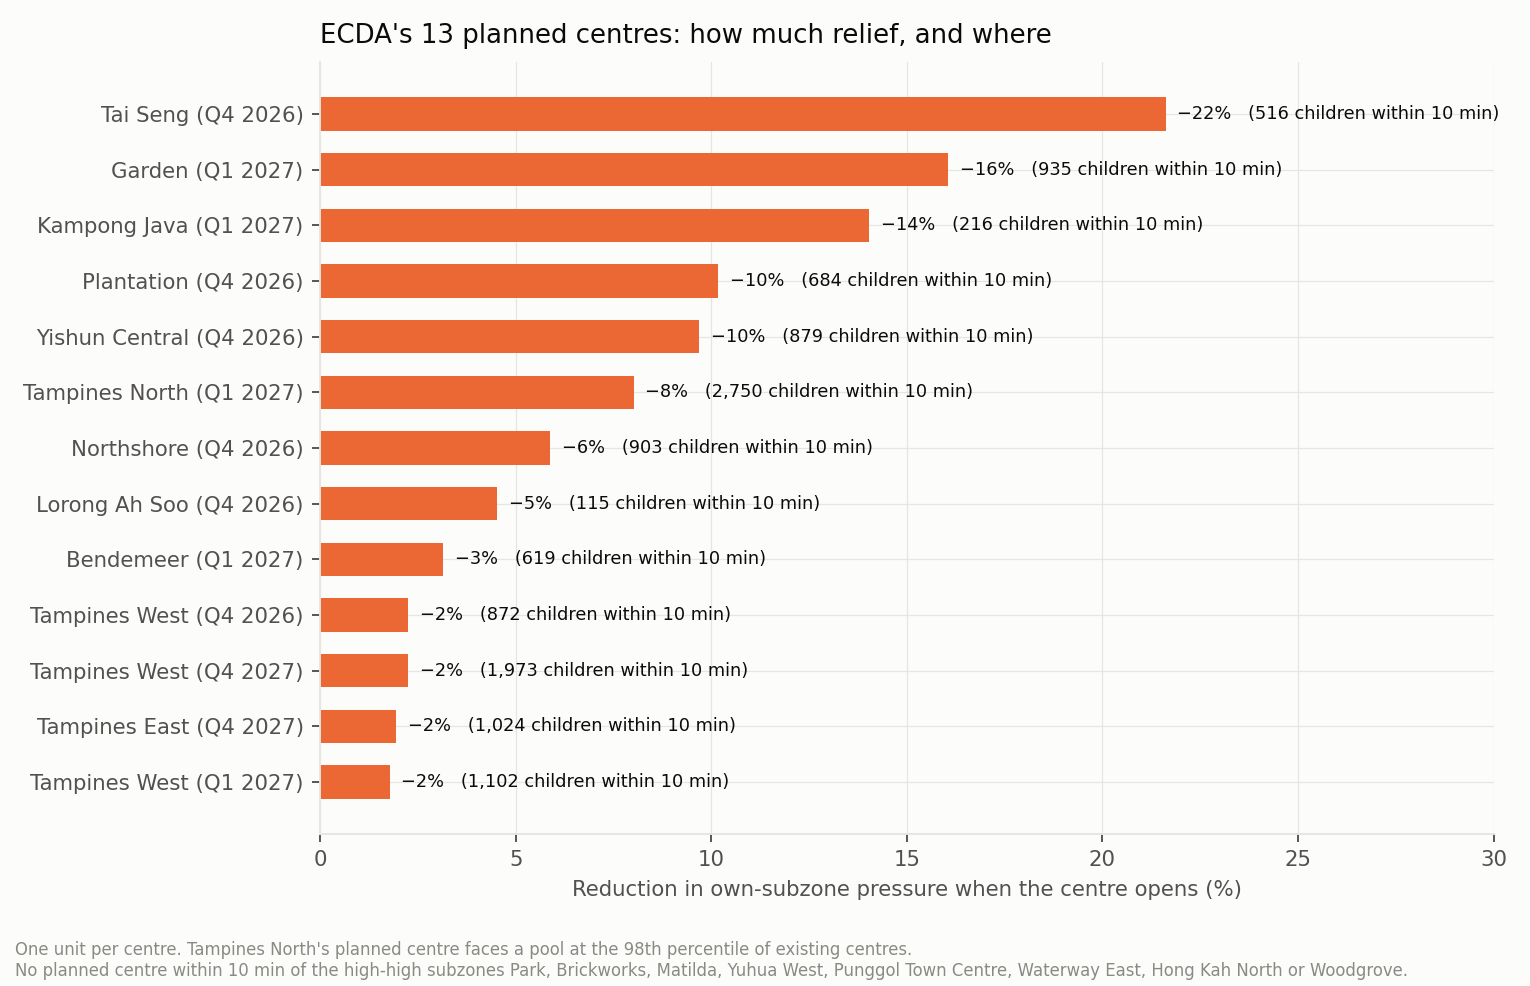

In [12]:
show(FIG / "lisa_vs_planned.png", 980)

# 1. Each planned centre added alone to the baseline: its pool and the relief it brings its own subzone.
impact = pd.read_csv(OUT / "planned_centre_impact.csv").sort_values("own_subzone_pct_change")
impact["centre"] = impact["centre_name"].str.replace(r"\(unnamed ECDA entry.*", "(unnamed ECDA entry)", regex=True).str[:48]
table(impact[["tp_code", "centre", "SUBZONE_N", "PLN_AREA_N", "pool_children_0_6", "pool_percentile_vs_existing",
              "own_subzone_pressure_before", "own_subzone_pct_change"]], "{:,.0f}")
pools = pd.read_csv(OUT / "centre_catchment_pools.csv")["pool_children_0_6_10min"]
print(f"for scale, an existing centre's pool: median {pools.median():,.0f} children, 90th percentile {pools.quantile(.9):,.0f}")
show(FIG / "planned_centre_relief.png", 880)

Two planned centres sit in Tengah and one in Tampines North, on our hottest spots: an outside agency,
using its own methods, is pointing at the same places. That is independent evidence the index measures
something real. But Tampines North's new centre opens into a pool of about 2,750 children, the 98th
percentile of existing centres, and cuts that subzone's pressure by only 8%: a start, not a fix.

**And the gap.** Our twenty weak links are the fifteen highest-pressure subzones plus the ten high-high
clusters (they overlap). How many have a planned centre within a ten-minute walk of their children?

In [13]:
gap = pd.read_csv(OUT / "planned_centre_gap.csv")
none = gap[gap["planned_centres_n"] == 0]
print(f"{len(none)} of the {len(gap)} weak-link subzones have no planned centre within 10 min of any of their blocks")
hh_gap = none[none["lisa_q"] == "HH"]
print(f"among them {len(hh_gap)} high-high clusters holding {hh_gap['children_0_6'].sum():,.0f} children aged 0-6: "
      f"{', '.join(hh_gap['SUBZONE_N'].str.title())}")
table(none.sort_values("pressure_base", ascending=False)[["SUBZONE_N", "PLN_AREA_N", "children_0_6", "pressure_base", "lisa_q"]], "{:,.0f}")

16 of the 20 weak-link subzones have no planned centre within 10 min of any of their blocks
among them 8 high-high clusters holding 16,835 children aged 0-6: Park, Brickworks, Matilda, Yuhua West, Punggol Town Centre, Waterway East, Hong Kah North, Woodgrove


SUBZONE_N,PLN_AREA_N,children_0_6,pressure_base,lisa_q
PARK,TENGAH,"1,230",318,HH
GOMBAK,BUKIT BATOK,223,309,ns
SEMBAWANG EAST,SEMBAWANG,"2,336",246,ns
WOODLANDS WEST,WOODLANDS,"2,206",241,ns
BRICKWORKS,BUKIT BATOK,"3,741",222,HH
MATILDA,PUNGGOL,"3,565",197,HH
BIDADARI,TOA PAYOH,"1,930",195,ns
BOON LAY PLACE,JURONG WEST,"1,705",186,ns
YISHUN EAST,YISHUN,"5,860",179,ns
TOA PAYOH WEST,TOA PAYOH,661,179,ns


## 7. The verdict

**Three recommendations.**

1. **Target the high-pressure clusters.** Park in Tengah, Brickworks in Bukit Batok and Punggol Town Centre:
   high-high clusters with nothing in the pipeline within a ten-minute walk (the gap table above lists all eight).
2. **Align the pipeline with demand.** Tampines North needs more than one centre; Bukit Batok and
   Punggol need their first.
3. **Protect affordability where fees are highest.** Fees cluster in the central high-high areas at
   over S$2,000 a month; Outram and Bukit Merah show that anchor-operator centres can sit inside that
   ring. That is where to watch that affordable options stay within reach.

The thesis sits in the last column of the table below: in the ten high-pressure subzones, every centre
already sits at the anchor-operator fee. There, money is not what is missing. Places are.

median listed fee in the ten high-pressure (HH) subzones: S$610 to S$755 (median S$610)
median listed fee in the eight central high-fee (HH) planning areas: S$2,100 to S$3,010


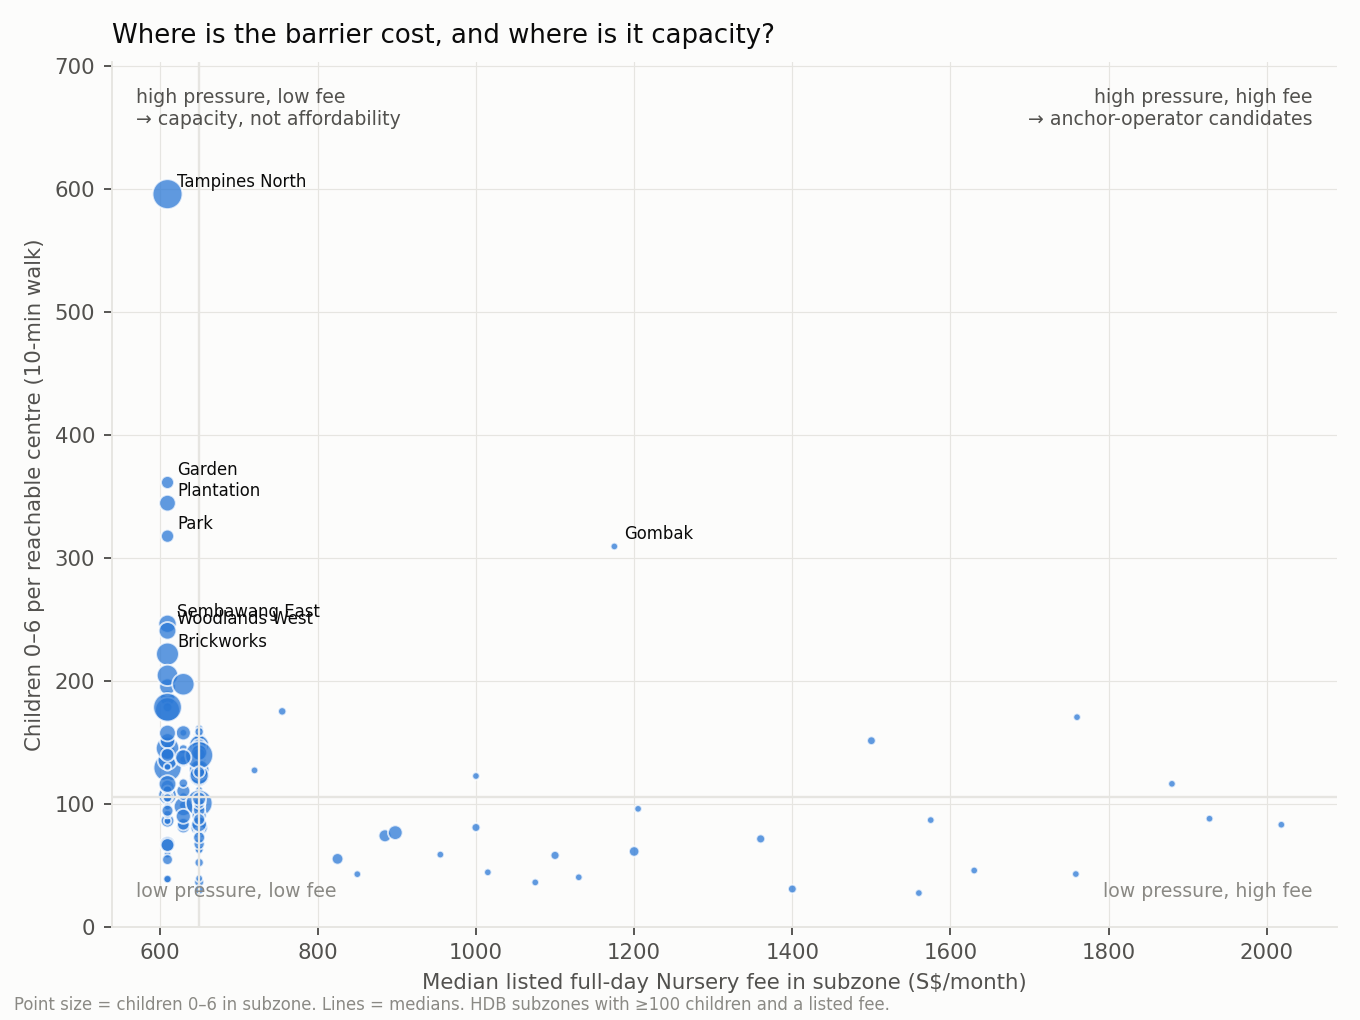

In [14]:
central_hh = fee_pa[fee_pa["lisa_cluster_p05"] == "High-High"]["median_fee_sgd"]
print(f"median listed fee in the ten high-pressure (HH) subzones: S${hh['median_fee_listed'].min():,.0f} to S${hh['median_fee_listed'].max():,.0f} "
      f"(median S${hh['median_fee_listed'].median():,.0f})")
print(f"median listed fee in the eight central high-fee (HH) planning areas: S${central_hh.min():,.0f} to S${central_hh.max():,.0f}")
show(FIG / "pressure_vs_fee.png", 760)

**Four answers, one finding.**

| Question | Answer | Evidence |
|---|---|---|
| Where are families and centres concentrated? | Demand clusters in the north-east; centres follow children at two-thirds the rate | I = 0.19; elasticity 0.65; Ripley's K clustered for both |
| How are fees spread, and do they follow income? | Fees cluster in the centre and rise S$114 per S$1,000 of income, one national slope | I = 0.51; OLS R² 0.63; GWR stationarity p = 0.35 |
| How does walking access vary? | It barely does: median 3 minutes, flat across income and flat type | 84% of children within 5 min; 99.8% within 10 |
| Where should new centres go? | Where supply is stretched: Tengah, Bukit Batok, Punggol, and the Tampines North peak | pressure LISA I = 0.18; 16 of 20 weak links have no planned centre in reach |

The gap in childcare access for HDB families is not distance and it is not price. It is **capacity in
fast-growing new towns**. Equitable access means a centre with room, not just a centre nearby.

**Limitations, each with its next step.** Demand counts HDB children only (add URA private-property
points to the pool). Centres count as one unit each (weight by licensed capacity when ECDA publishes
it). Walking times are modelled on OpenStreetMap, not observed (validate a sample against OneMap
routing). This is one snapshot of towns still being built (re-run the index on each new listing;
`run_all.ipynb` makes that a four-minute job).

## Where to read more

| Section above | Notebook | What it adds beyond this page |
|---|---|---|
| 1 | `1_02`, `1_04`, `1_05`, `1_06`, `1_07` | The HDB join, the child allocation, the centre layer and its QA, the walk matrix, the subzone table |
| 2 | `2_01`–`2_05`, `3_04` | Income bands, the KDE, Ripley's K with its simulation band, the H-a fit, child-density LISA |
| 3 | `3_01`, `3_02`, `3_03` | Moran scatter and permutation histogram, OLS diagnostics and influence, GWR bandwidth and local slopes |
| 4 | `2_04`, `3_07` | Route samples, distance maps, Spearman and Kruskal-Wallis by tercile |
| 5 | `3_05`, `3_06` | The proposal's bivariate H-c (rejected), the 2SFCA variants (15 min, full-day only), LISA robustness |
| 6 | `3_08` | Each planned centre's catchment and the full gap table |